# 03 · Plot results

Reads the results stored under `results/raw/<model>/<track>.parquet` (written by `02_evaluation_loop`) and plots them. Nothing here re-runs a model, so it is safe to run while an evaluation is in progress: it sees the last checkpoint.

1. Coverage: which models and tracks have results
2. RMSE relative to the baseline model, every model × track
3. MASE, every model × track
4. Classical vs quantum tracks
5. Error over time
6. Recessions vs expansions
7. Example series: forecast vs actual for each model
8. Compute time
9. Metric by model: one track, every target

Edit the lists in the next cell to choose what is plotted. Figures are saved to `results/figures/`.

In [1]:
# ---- Models and tracks to plot ----
MODEL_LIST = ["random_walk", "AR6", "arima", "linear_readout",                 # benchmarks
              "decision_tree", "adaboost", "random_forest", "xgboost",         # tree-based
              "linear_svm", "sig_kernel"]                                      # kernel-based  # models with results under results/raw; None = every model with results
TRACK_LIST = None                             # e.g. ["B", "CRC", "QRC"]; None = every track with results
BASELINE_MODEL = "random_walk"                # relative metrics divide by this model on the same track, target, horizon and folds

# ---- Classical vs quantum ----
QUANTUM_TRACKS = ["Q_su_pce", "Q_su_pauli", "Q_su_bitstring", "Q_su_single_bit", "Q_heisenberg_pce"]  # every other track counts as classical
TRACK_PAIRS = [(q, "B") for q in QUANTUM_TRACKS]  # (quantum, classical): each quantum track vs its raw input

# ---- Time-series plots ----
TIME_TRACK     = "B"                          # track for the error-over-time and regime plots
TIME_HORIZON   = 1
ROLLING_WINDOW = 36                           # months
EXAMPLE_TRACKS  = ["B", "Q_su_pce"]              # tracks shown in the forecast-vs-actual plots (missing ones are skipped)
EXAMPLE_HORIZON = 1
EXAMPLE_PERIOD  = ("2005-01-01", "2012-12-01")

RESULTS_DIR = None                            # None = <repo>/results

## Setup

In [2]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

if "google.colab" in sys.modules:  # repo cloned by 02_evaluation_loop's setup cell
    REPO_ROOT = Path("/content/capstone-quantum")
    sys.path.insert(0, str(REPO_ROOT))
else:
    REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

from src.evaluation import explode_predictions, load_results
from src.models import MODEL_REGISTRY

DATA_DIR    = REPO_ROOT / "data" / "processed"
RESULTS_DIR = Path(RESULTS_DIR) if RESULTS_DIR else REPO_ROOT / "results"
FIG_DIR     = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

load_models = None if MODEL_LIST is None else list(dict.fromkeys([BASELINE_MODEL, *MODEL_LIST]))

raw = load_results(RESULTS_DIR, models=load_models, tracks=TRACK_LIST)
ok  = raw[raw["error"].isna()].copy()
usrec = pd.read_parquet(DATA_DIR / "usrec.parquet").iloc[:, 0].rename("usrec")

# display order: MODEL_LIST order (else registry order), tracks classical first, then quantum
order_models = MODEL_LIST or [*MODEL_REGISTRY, *sorted(set(ok["model"]) - set(MODEL_REGISTRY))]
MODELS  = [m for m in order_models if m in set(ok["model"])]
TRACK_ORDER = ["A", "B", "C", "D", "D_mini", "CRC", "QRC"]
TRACKS  = sorted(set(ok["track"]), key=lambda t: (t in QUANTUM_TRACKS, TRACK_ORDER.index(t) if t in TRACK_ORDER else 99, t))
TARGETS = [t for t in ["INDPRO", "PAYEMS", "CPIAUCSL", "S&P 500"] if t in set(ok["target"])] + \
          sorted(set(ok["target"]) - {"INDPRO", "PAYEMS", "CPIAUCSL", "S&P 500"})
HORIZONS = sorted(ok["horizon"].unique())
COLS = pd.MultiIndex.from_product([TARGETS, HORIZONS], names=["target", "horizon"])

missing = [m for m in (MODEL_LIST or []) if m not in MODELS]
if missing:
    print(f"No results on disk for: {missing}")
if BASELINE_MODEL not in MODELS:
    raise ValueError(f"Baseline {BASELINE_MODEL!r} has no results; set BASELINE_MODEL to one of {MODELS}")
print(f"Models: {MODELS}")
print(f"Tracks: {TRACKS}  (quantum: {[t for t in TRACKS if t in QUANTUM_TRACKS]})")

Models: ['random_walk', 'AR6', 'arima', 'linear_readout', 'decision_tree', 'adaboost', 'random_forest', 'xgboost', 'linear_svm', 'sig_kernel']
Tracks: ['A', 'B', 'Q_heisenberg_pce', 'Q_su_bitstring', 'Q_su_pauli', 'Q_su_pce', 'Q_su_single_bit']  (quantum: ['Q_heisenberg_pce', 'Q_su_bitstring', 'Q_su_pauli', 'Q_su_pce', 'Q_su_single_bit'])


In [3]:
MODEL_LABELS = {
    "random_walk": "Random walk", "AR6": "AR(6)", "arima": "ARIMA",
    "adaboost": "AdaBoost", "random_forest": "Random forest", "adaboost_di": "AdaBoost (DI)",
    "knn_di": "KNN (DI)", "svr_linear_di": "Linear SVR (DI)", "xgboost_di": "XGBoost (DI)",
    "decision_tree": "Decision tree", "xgboost": "XGBoost", "linear_readout": "Perceptron (ridge)",
    "linear_svm": "Linear SVM", "sig_kernel": "Signature kernel",
}
TRACK_LABELS = {
    "A": "A · full panel", "B": "B · curated", "C": "C · LASSO", "D": "D · PCA", "D_mini": "D-mini · PCA",
    "CRC": "CRC · classical reservoir", "QRC": "QRC · quantum reservoir",
}
mlabel = lambda m: MODEL_LABELS.get(m, m)
tlabel = lambda t: TRACK_LABELS.get(t, t)


INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

# Colour by model family: one hue per family, shaded dark -> light within it. The four family
# hues pass the palette checks against each other (all pairs, light surface). Shades within a
# family are deliberately close, so a model is never identified by colour alone: bars carry
# model labels and lines also get a dash style per model.
MODEL_FAMILIES = {
    "Benchmark":    ["random_walk", "AR6", "arima", "linear_readout"],
    "Tree-based":   ["decision_tree", "adaboost", "random_forest", "xgboost", "adaboost_di", "xgboost_di"],
    "Kernel-based": ["linear_svm", "sig_kernel", "svr_linear_di"],
    "RNN":          ["rnn", "gru"],
}
FAMILY_SHADES = {  # dark -> light, constant OKLCH hue per family
    "Benchmark":    ["#054f9d", "#1769c5", "#3884e4", "#549efc"],
    "Tree-based":   ["#085f40", "#0b7c55", "#0d9a6a", "#2db983"],
    "Kernel-based": ["#785004", "#9a6702", "#bb8013", "#e09913"],
    "RNN":          ["#a8031a", "#ca2f33", "#ea504e", "#fe7b74"],
}
DASHES = ["-", "--", ":", "-."]
MODEL_FAMILY = {m: f for f, members in MODEL_FAMILIES.items() for m in members}

MODEL_COLOR, MODEL_DASH = {}, {}
for family, shades in FAMILY_SHADES.items():
    members = [m for m in MODELS if MODEL_FAMILY.get(m) == family]
    for i, m in enumerate(members):
        # spread the family's models across its shades, in MODEL_LIST order
        k = round(i * (len(shades) - 1) / (len(members) - 1)) if len(members) > 1 else 1
        MODEL_COLOR[m], MODEL_DASH[m] = shades[k], DASHES[i % len(DASHES)]
for m in MODELS:  # models outside every family are drawn grey as "Other"
    MODEL_COLOR.setdefault(m, MUTED)
    MODEL_DASH.setdefault(m, "-")


def family_legend(fig, models, **kwargs):
    """Figure legend with one swatch per model family present in `models`."""
    present = {MODEL_FAMILY.get(m, "Other") for m in models}
    names = [f for f in [*MODEL_FAMILIES, "Other"] if f in present]
    handles = [Patch(color=FAMILY_SHADES[f][1] if f in FAMILY_SHADES else MUTED, label=f) for f in names]
    fig.legend(handles=handles, ncol=len(handles), **kwargs)
ACTUAL_COLOR, FORECAST_COLOR = INK_2, "#2a78d6"
# diverging: blue = better than the comparison, grey = equal, red = worse
DIVERGING = LinearSegmentedColormap.from_list(
    "better_worse", ["#184f95", "#3987e5", "#9ec5f4", "#f0efec", "#f2a7a6", "#e34948", "#a32a2a"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.titlesize": 11,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "figure.dpi": 110,
})

FOLD_KEYS = ["target", "horizon", "fold_id"]


def matched_ratio(num, den, on, by):
    """
    RMSE(num) / RMSE(den) over the folds both have, grouped by `by`.
    Also returns win_rate: share of those folds where num's absolute error is smaller.
    """
    m = num.merge(den[on + ["mse", "mae"]], on=on, suffixes=("_n", "_d"))
    g = m.groupby(by)
    return pd.DataFrame({
        "ratio":    (g["mse_n"].mean() / g["mse_d"].mean()) ** 0.5,
        "win_rate": (m["mae_n"] < m["mae_d"]).groupby([m[c] for c in by]).mean(),
        "folds":    g.size(),
    })


def wide(series, rows):
    """Series indexed by (row, target, horizon) -> rows x (target, horizon) table."""
    return series.unstack(["target", "horizon"]).reindex(index=rows, columns=COLS)


def recession_spans(flag):
    runs = (flag != flag.shift()).cumsum()
    return [(g.index[0], g.index[-1] + pd.offsets.MonthEnd(0)) for _, g in flag[flag == 1].groupby(runs[flag == 1])]


def shade_recessions(ax, start, end):
    for s, e in recession_spans(usrec.loc[start:end]):
        ax.axvspan(s, e, color=GRID, linewidth=0, zorder=0)


LIMIT = 1.0  # colour saturates at 2^±1, i.e. 0.5x and 2x; cells still print the exact value


def ratio_heatmap(ax, table, title, fmt="{:.2f}"):
    """Rows x (target, horizon) table of ratios, coloured on a log scale centred at 1."""
    vals = np.log2(table.values.astype(float))
    im = ax.imshow(np.clip(vals, -LIMIT, LIMIT), cmap=DIVERGING, vmin=-LIMIT, vmax=LIMIT, aspect="auto")
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = table.values[i, j]
            text = "–" if np.isnan(v) else fmt.format(v)
            color = MUTED if np.isnan(v) else (SURFACE if abs(vals[i, j]) > 0.65 else INK)
            ax.text(j, i, text, ha="center", va="center", fontsize=8.5, color=color)
    ax.set_yticks(range(len(table.index)), [mlabel(r) for r in table.index])
    ax.set_xticks(range(len(table.columns)), [f"{t}\nh={h}" for t, h in table.columns], fontsize=8.5)
    ax.xaxis.tick_top()
    # 2px surface gaps between cells
    ax.set_xticks(np.arange(-0.5, len(table.columns)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(table.index)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_title(title, loc="left", pad=6, fontsize=11)
    return im


def heatmap_figure(panels, suptitle, colorbar_label):
    """panels: list of (title, table). One heatmap per panel, stacked, with one shared colour scale."""
    heights = [max(len(t.index), 1) * 0.42 + 1.1 for _, t in panels]
    fig, axes = plt.subplots(len(panels), 1, figsize=(13, sum(heights) + 0.8), layout="constrained",
                             gridspec_kw={"height_ratios": heights}, squeeze=False)
    for ax, (title, table) in zip(axes[:, 0], panels):
        im = ratio_heatmap(ax, table, title)
    ticks = np.log2([0.5, 0.71, 1, 1.41, 2])
    cbar = fig.colorbar(im, ax=axes[:, 0], ticks=ticks, fraction=0.025, pad=0.01, aspect=30)
    cbar.ax.set_yticklabels(["≤0.5×", "0.71×", "1×", "1.41×", "≥2×"])
    cbar.set_label(colorbar_label, color=INK_2)
    cbar.outline.set_visible(False)
    fig.suptitle(suptitle, x=0.01, ha="left", fontsize=12)
    fig.get_layout_engine().set(h_pad=0.25)
    return fig


def log_ratio_axis(ax, lo, hi):
    ax.set_yscale("log")
    fmt = mticker.FuncFormatter(lambda v, _: f"{v:g}×")
    if hi / lo >= 3:
        ax.yaxis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5)))
        ax.yaxis.set_major_formatter(fmt)
        ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    else:
        ax.yaxis.set_major_formatter(fmt)
        ax.yaxis.set_minor_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}×" if round(v, 1) == round(v, 4) else ""))


def rolling_ratio_figure(merged, suptitle, window=ROLLING_WINDOW):
    """merged: rows of a num/den merge with mae_n, mae_d, test_start. One panel per target, one line per model."""
    lines = [m for m in MODELS if m in set(merged["model"])]
    fig, axes = plt.subplots(len(TARGETS), 1, figsize=(12, 2.3 * len(TARGETS)), sharex=True, squeeze=False)
    for ax, target in zip(axes[:, 0], TARGETS):
        sub = merged[merged["target"] == target]
        vals = []
        for model in lines:
            d = sub[sub["model"] == model].sort_values("test_start").set_index("test_start")
            r = d["mae_n"].rolling(window, min_periods=window).mean() / d["mae_d"].rolling(window, min_periods=window).mean()
            if r.notna().any():
                ax.plot(r.index, r, color=MODEL_COLOR[model], linestyle=MODEL_DASH[model], linewidth=1.6, label=mlabel(model))
                vals.append(r.dropna())
        if not vals:
            ax.set_title(f"{target} · not enough folds for a {window}-month window", loc="left")
            continue
        shade_recessions(ax, sub["test_start"].min(), sub["test_start"].max())
        ax.axhline(1.0, color=INK_2, linewidth=1)
        allv = pd.concat(vals)
        log_ratio_axis(ax, min(allv.min(), 1.0), max(allv.max(), 1.0))
        ax.set_title(target, loc="left")
        ax.set_ylabel("MAE ratio (log)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    ncol = max(min(len(labels), 5), 1)
    header = 0.45 + 0.28 * -(-len(labels) // ncol)  # inches above the panels: title plus legend rows
    top = 1 - header / fig.get_figheight()
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.suptitle(suptitle, x=0.01, y=1.0, ha="left", va="top", fontsize=12)
    fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 1 - 0.4 / fig.get_figheight()), ncol=ncol)
    return fig


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Coverage

Runs stored per model and track. Comparisons below only use folds that both sides have, so a partial run (for example a smoke test) is compared on its own folds only.

In [4]:
coverage = raw.groupby(["model", "track"]).agg(
    runs=("fold_id", "size"),
    errors=("error", lambda e: e.notna().sum()),
    with_predictions=("y_pred", lambda p: p.notna().sum()),
)
coverage.unstack("track").reindex(index=[m for m in order_models if m in set(raw["model"])])

runs                                                     \
track                A       B Q_heisenberg_pce Q_su_bitstring Q_su_pauli   
model                                                                       
random_walk        NaN  7724.0           7724.0         7724.0     7724.0   
AR6                NaN  7724.0           7724.0         7724.0     7724.0   
arima              NaN  7724.0              NaN            NaN        NaN   
linear_readout     NaN  7724.0           7724.0         7724.0     7724.0   
decision_tree   7724.0  7724.0              NaN            NaN        NaN   
adaboost        7724.0  7724.0              NaN            NaN        NaN   
random_forest   7724.0  7724.0              NaN            NaN        NaN   
xgboost         7724.0  7724.0              NaN            NaN        NaN   
linear_svm         NaN  7724.0              NaN            NaN        NaN   
sig_kernel         NaN  7724.0              NaN            NaN        NaN   

                                        errors                        ...  \
track          Q_su_pce Q_su_single_bit      A    B Q_heisenberg_pce  ...   
model                                                                 ...   
random_walk      7724.0          7724.0    NaN  0.0              0.0  ...   
AR6              7724.0          7724.0    NaN  0.0              0.0  ...   
arima               NaN             NaN    NaN  0.0              NaN  ...   
linear_readout   7724.0          7724.0    NaN  0.0              0.0  ...   
decision_tree       NaN             NaN    0.0  0.0              NaN  ...   
adaboost            NaN             NaN    0.0  0.0              NaN  ...   
random_forest       NaN             NaN    0.0  0.0              NaN  ...   
xgboost             NaN             NaN    0.0  0.0              NaN  ...   
linear_svm          NaN             NaN    NaN  0.0              NaN  ...   
sig_kernel          NaN             NaN    NaN  0.0              NaN  ...   

                                                   with_predictions          \
track          Q_su_pauli Q_su_pce Q_su_single_bit                A       B   
model                                                                         
random_walk           0.0      0.0             0.0              NaN  7724.0   
AR6                   0.0      0.0             0.0              NaN  7724.0   
arima                 NaN      NaN             NaN              NaN     0.0   
linear_readout        0.0      0.0             0.0              NaN  7724.0   
decision_tree         NaN      NaN             NaN           7724.0  7724.0   
adaboost              NaN      NaN             NaN           7724.0  7724.0   
random_forest         NaN      NaN             NaN           7724.0  7724.0   
xgboost               NaN      NaN             NaN           7724.0  7724.0   
linear_svm            NaN      NaN             NaN              NaN  7724.0   
sig_kernel            NaN      NaN             NaN              NaN  7724.0   

                                                                    \
track          Q_heisenberg_pce Q_su_bitstring Q_su_pauli Q_su_pce   
model                                                                
random_walk              7724.0         7724.0     7724.0   7724.0   
AR6                      7724.0         7724.0     7724.0   7724.0   
arima                       NaN            NaN        NaN      NaN   
linear_readout           7724.0         7724.0     7724.0   7724.0   
decision_tree               NaN            NaN        NaN      NaN   
adaboost                    NaN            NaN        NaN      NaN   
random_forest               NaN            NaN        NaN      NaN   
xgboost                     NaN            NaN        NaN      NaN   
linear_svm                  NaN            NaN        NaN      NaN   
sig_kernel                  NaN            NaN        NaN      NaN   

                                
track          Q_su_single_bit  
model    

## 2. RMSE relative to the baseline

For each model, track, target and horizon: RMSE over the folds it shares with the baseline model on the same track, divided by the baseline's RMSE on those folds. Blue beats the baseline, red loses to it. Colour saturates at 0.5× and 2×; the number in each cell is exact.

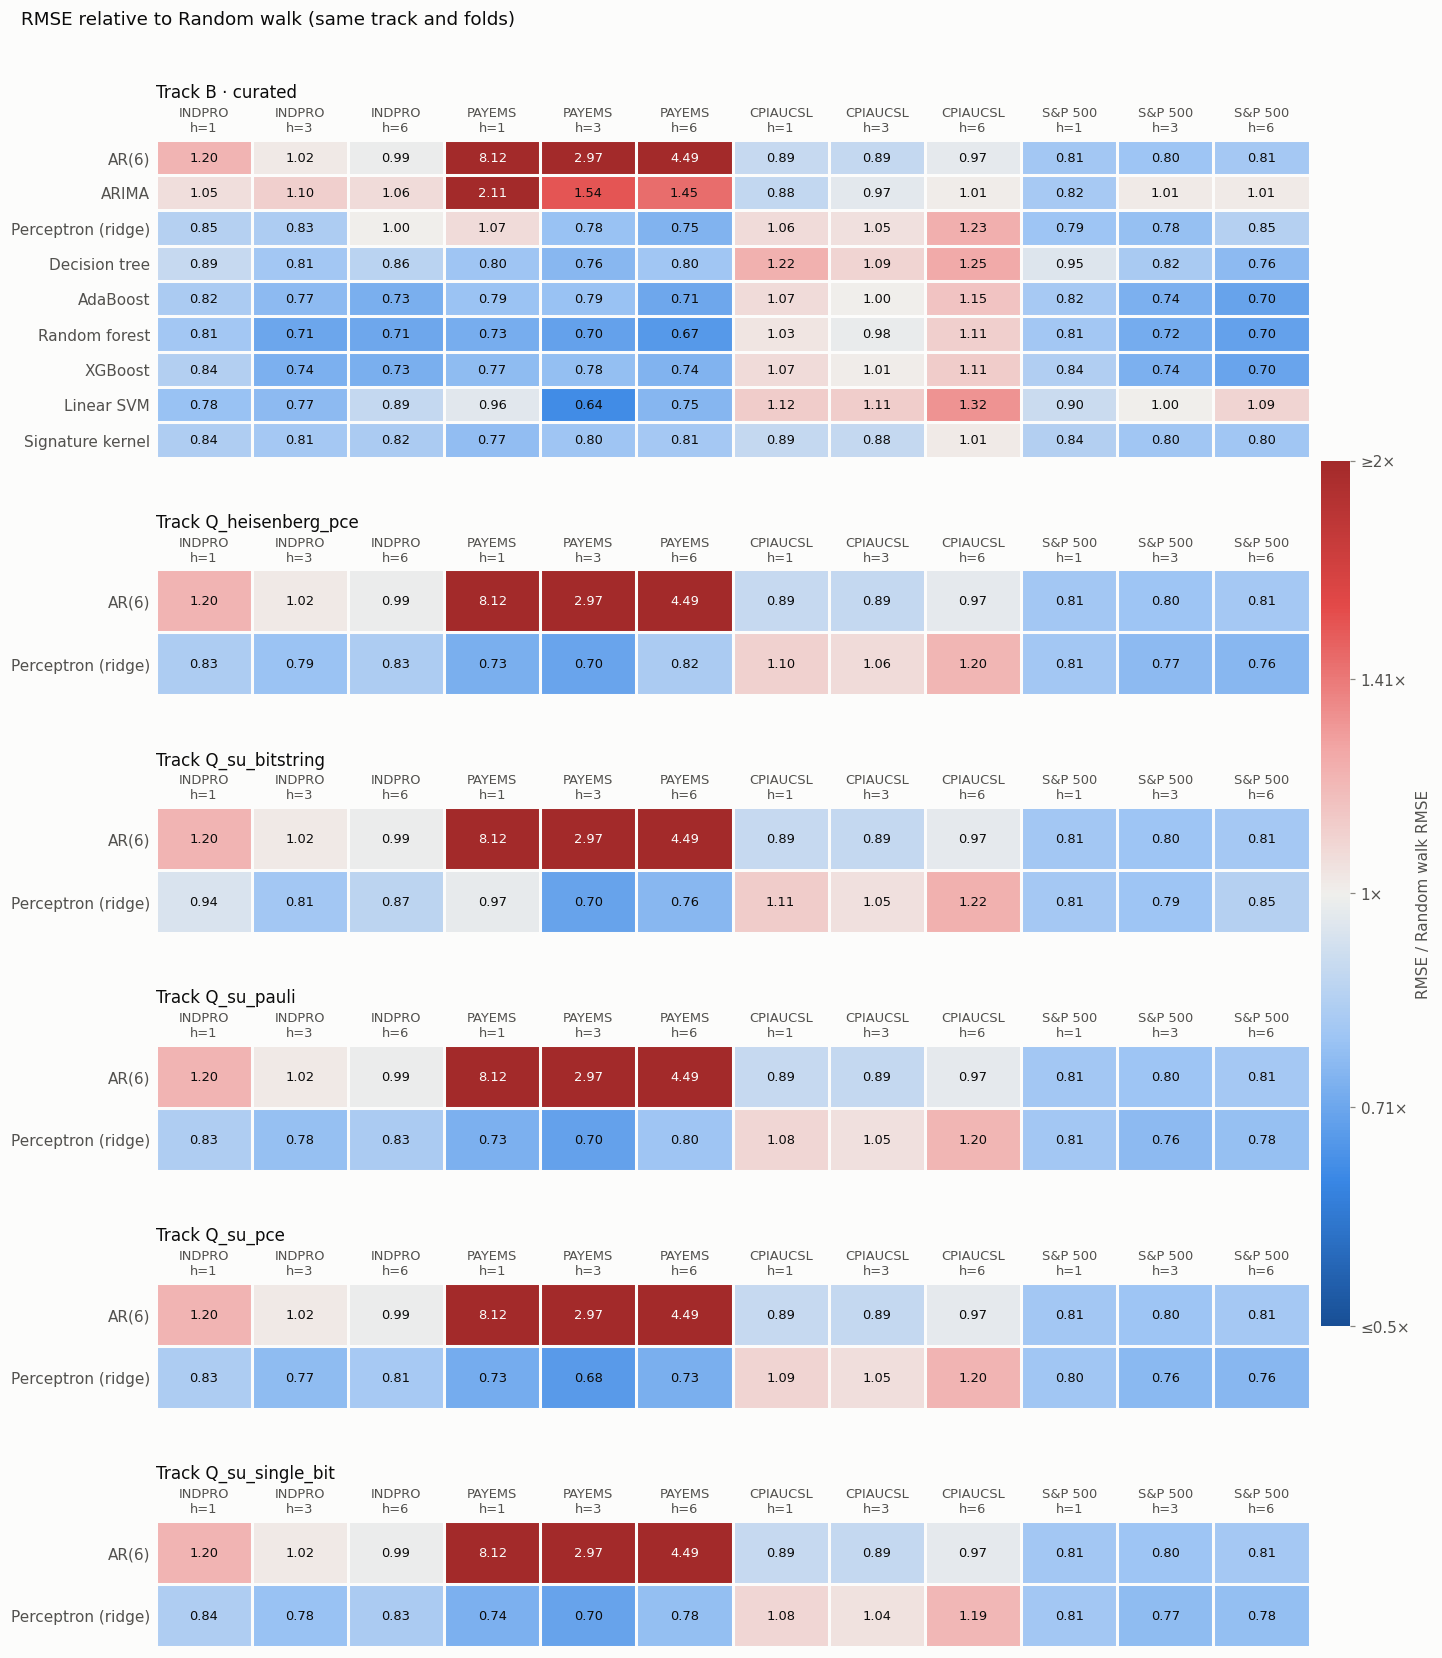

In [5]:
base = ok[ok["model"] == BASELINE_MODEL]
others = [m for m in MODELS if m != BASELINE_MODEL]
vs_base = matched_ratio(ok[ok["model"] != BASELINE_MODEL], base,
                        on=["track", *FOLD_KEYS], by=["track", "model", "target", "horizon"])

if others and not vs_base.empty:
    panels = [(f"Track {tlabel(t)}", wide(vs_base.loc[t, "ratio"], [m for m in others if m in vs_base.loc[t].index.get_level_values("model")]))
              for t in TRACKS if t in vs_base.index.get_level_values("track")]
    fig = heatmap_figure(panels, f"RMSE relative to {mlabel(BASELINE_MODEL)} (same track and folds)",
                         f"RMSE / {mlabel(BASELINE_MODEL)} RMSE")
    save(fig, "relative_rmse_by_track")
    plt.show()
else:
    print("No model shares folds with the baseline; nothing to compare.")

## 3. MASE

Mean absolute scaled error averaged over folds, every model including the baseline. Each fold scales by the in-sample MAE of the h-step naive forecast, so below 1 beats that naive forecast.

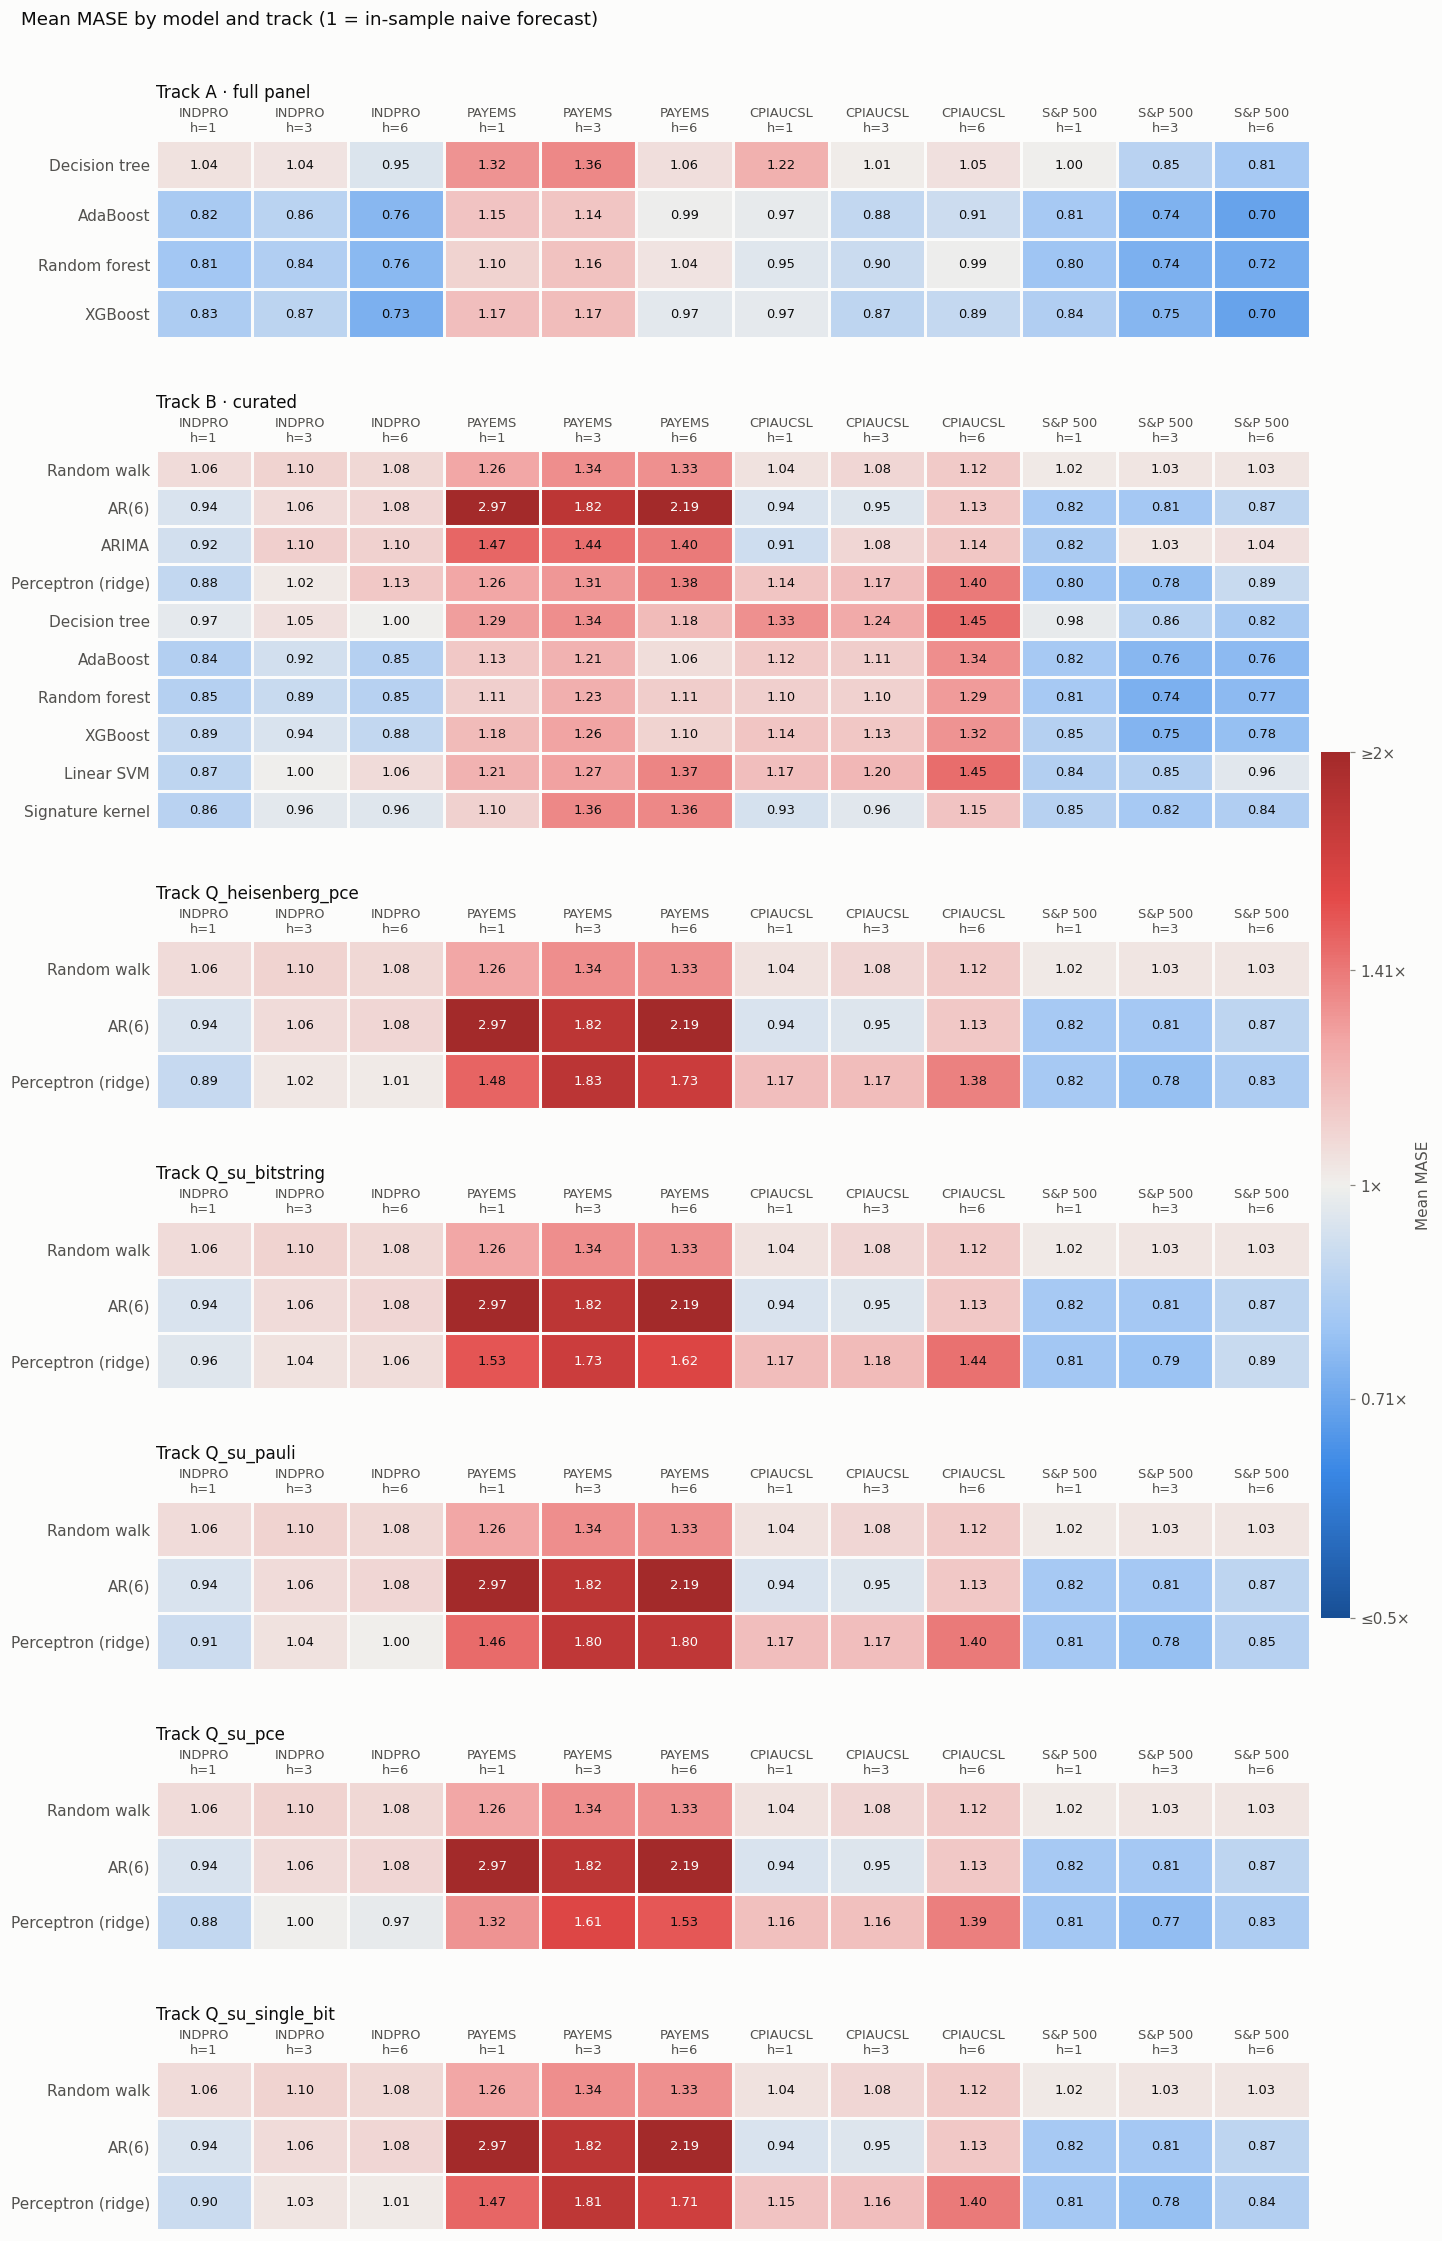

In [6]:
mase = ok.groupby(["track", "model", "target", "horizon"])["mase"].mean()
panels = [(f"Track {tlabel(t)}", wide(mase.loc[t], [m for m in MODELS if m in mase.loc[t].index.get_level_values("model")]))
          for t in TRACKS]
fig = heatmap_figure(panels, "Mean MASE by model and track (1 = in-sample naive forecast)", "Mean MASE")
save(fig, "mase_by_track")
plt.show()

## 4. Classical vs quantum tracks

### 4.1 Track pairs

For each pair in `TRACK_PAIRS` and each model run on both tracks: RMSE on the quantum track divided by RMSE on the classical track, over shared folds. Blue means the quantum features helped that model. `QRC` vs `CRC` separates the quantum reservoir from the reservoir idea itself; `QRC` vs `B` asks whether the reservoir beats its own raw inputs.

Q_su_pce vs B: identical results on both tracks (model ignores the features), not shown: ['random_walk', 'AR6']
Q_su_pauli vs B: identical results on both tracks (model ignores the features), not shown: ['random_walk', 'AR6']
Q_su_bitstring vs B: identical results on both tracks (model ignores the features), not shown: ['random_walk', 'AR6']
Q_su_single_bit vs B: identical results on both tracks (model ignores the features), not shown: ['random_walk', 'AR6']


Q_heisenberg_pce vs B: identical results on both tracks (model ignores the features), not shown: ['random_walk', 'AR6']


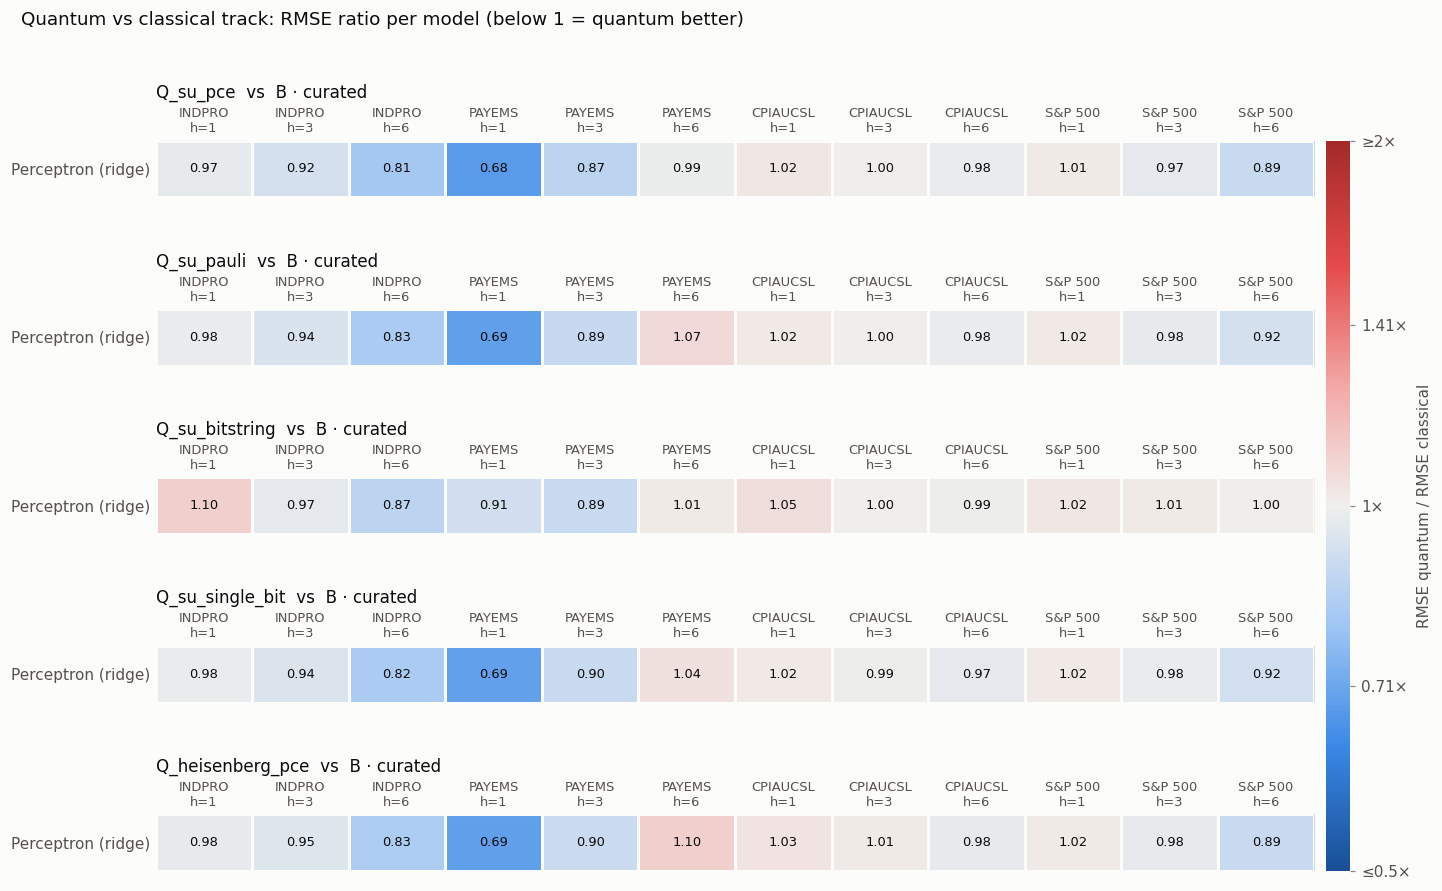

Q_su_pce vs B: share of folds where Q_su_pce has the smaller absolute error


target         INDPRO             PAYEMS             CPIAUCSL             \
horizon             1     3     6      1     3     6        1     3    6   
model                                                                      
linear_readout   0.48  0.53  0.52   0.43  0.38  0.44     0.47  0.51  0.5   

target         S&P 500              
horizon              1     3     6  
model                               
linear_readout    0.47  0.51  0.52

Q_su_pauli vs B: share of folds where Q_su_pauli has the smaller absolute error


target         INDPRO             PAYEMS             CPIAUCSL              \
horizon             1     3     6      1     3     6        1     3     6   
model                                                                       
linear_readout   0.45  0.46  0.53    0.4  0.35  0.35     0.47  0.49  0.49   

target         S&P 500              
horizon              1     3     6  
model                               
linear_readout    0.48  0.48  0.49

Q_su_bitstring vs B: share of folds where Q_su_bitstring has the smaller absolute error


target         INDPRO            PAYEMS             CPIAUCSL              \
horizon             1     3    6      1     3     6        1     3     6   
model                                                                      
linear_readout   0.41  0.49  0.5   0.37  0.39  0.43     0.49  0.48  0.49   

target         S&P 500              
horizon              1     3     6  
model                               
linear_readout    0.47  0.49  0.51

Q_su_single_bit vs B: share of folds where Q_su_single_bit has the smaller absolute error


target         INDPRO            PAYEMS             CPIAUCSL             \
horizon             1     3    6      1     3     6        1    3     6   
model                                                                     
linear_readout   0.46  0.46  0.5    0.4  0.35  0.38     0.49  0.5  0.49   

target         S&P 500             
horizon              1     3    6  
model                              
linear_readout    0.49  0.49  0.5

Q_heisenberg_pce vs B: share of folds where Q_heisenberg_pce has the smaller absolute error


target         INDPRO            PAYEMS             CPIAUCSL              \
horizon             1    3     6      1     3     6        1     3     6   
model                                                                      
linear_readout   0.47  0.5  0.52   0.41  0.35  0.36     0.49  0.48  0.52   

target         S&P 500             
horizon              1    3     6  
model                              
linear_readout    0.48  0.5  0.54

In [7]:
pair_tables, pair_results = [], {}
for q, c in TRACK_PAIRS:
    if q not in TRACKS or c not in TRACKS:
        print(f"Skipping {q} vs {c}: no results for {[t for t in (q, c) if t not in TRACKS]}")
        continue
    res = matched_ratio(ok[ok["track"] == q], ok[ok["track"] == c],
                        on=["model", *FOLD_KEYS], by=["model", "target", "horizon"])
    if res.empty:
        print(f"Skipping {q} vs {c}: no model has results on both")
        continue
    # models that ignore the features (e.g. random walk, AR) score identically on both tracks: leave them out
    same = res["ratio"].sub(1).abs().groupby("model").max() < 1e-9
    if same.any():
        print(f"{q} vs {c}: identical results on both tracks (model ignores the features), not shown: "
              f"{[m for m in MODELS if same.get(m, False)]}")
    res = res[~res.index.get_level_values("model").isin(same[same].index)]
    if res.empty:
        continue
    pair_results[(q, c)] = res
    rows = [m for m in MODELS if m in res.index.get_level_values("model")]
    pair_tables.append((f"{tlabel(q)}  vs  {tlabel(c)}", wide(res["ratio"], rows)))

if pair_tables:
    fig = heatmap_figure(pair_tables, "Quantum vs classical track: RMSE ratio per model (below 1 = quantum better)",
                         "RMSE quantum / RMSE classical")
    save(fig, "quantum_vs_classical_pairs")
    plt.show()
    for (q, c), res in pair_results.items():
        print(f"{q} vs {c}: share of folds where {q} has the smaller absolute error")
        display(wide(res["win_rate"], [m for m in MODELS if m in res.index.get_level_values("model")]).round(2))

### 4.2 Best quantum vs best classical track

For each model, target and horizon: the lowest RMSE on any quantum track divided by the lowest RMSE on any classical track. Picking the best track after the fact is an in-sample choice, so read this as a ceiling for each side rather than an out-of-sample result. Unlike 4.1, each track's RMSE uses all of its own folds.

Identical on every track (model ignores the features), not shown: ['random_walk', 'AR6']


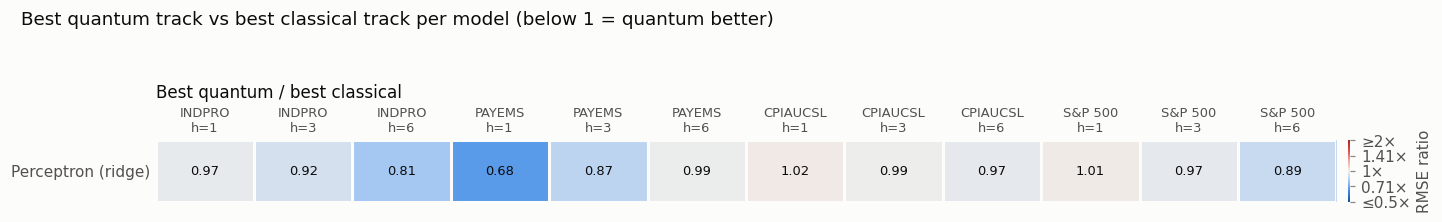

Best classical track per cell:


target         INDPRO       PAYEMS       CPIAUCSL       S&P 500      
horizon             1  3  6      1  3  6        1  3  6       1  3  6
model                                                                
linear_readout      B  B  B      B  B  B        B  B  B       B  B  B

In [8]:
q_tracks = [t for t in TRACKS if t in QUANTUM_TRACKS]
c_tracks = [t for t in TRACKS if t not in QUANTUM_TRACKS]
if q_tracks and c_tracks:
    rmse_mt = (ok.groupby(["model", "track", "target", "horizon"])["mse"].mean() ** 0.5).rename("rmse").reset_index()
    rmse_mt["kind"] = np.where(rmse_mt["track"].isin(QUANTUM_TRACKS), "quantum", "classical")
    best = rmse_mt.loc[rmse_mt.groupby(["model", "target", "horizon", "kind"])["rmse"].idxmin()]
    best = best.pivot_table(index=["model", "target", "horizon"], columns="kind",
                            values=["rmse", "track"], aggfunc="first").dropna()
    ratio = (best[("rmse", "quantum")].astype(float) / best[("rmse", "classical")].astype(float)).rename("ratio")
    same = ratio.sub(1).abs().groupby("model").max() < 1e-9
    if same.any():
        print(f"Identical on every track (model ignores the features), not shown: {[m for m in MODELS if same.get(m, False)]}")
    rows = [m for m in MODELS if m in ratio.index.get_level_values("model") and not same.get(m, False)]
if q_tracks and c_tracks and rows:
    fig = heatmap_figure([("Best quantum / best classical", wide(ratio, rows))],
                         "Best quantum track vs best classical track per model (below 1 = quantum better)", "RMSE ratio")
    save(fig, "quantum_vs_classical_best")
    plt.show()
    print("Best classical track per cell:")
    display(wide(best[("track", "classical")], rows))
elif q_tracks and c_tracks:
    print("No feature-using model has results on both a quantum and a classical track.")
else:
    print(f"Needs results on at least one quantum track {QUANTUM_TRACKS} and one classical track; have {TRACKS}.\n"
          "Build the quantum tracks with scripts/build_quantum_tracks.py, then run 02_evaluation_loop on them.")

### 4.3 Track pairs over time

Rolling MAE on the quantum track divided by rolling MAE on the classical track, at `TIME_HORIZON`, one line per model. Grey bands are NBER recessions.

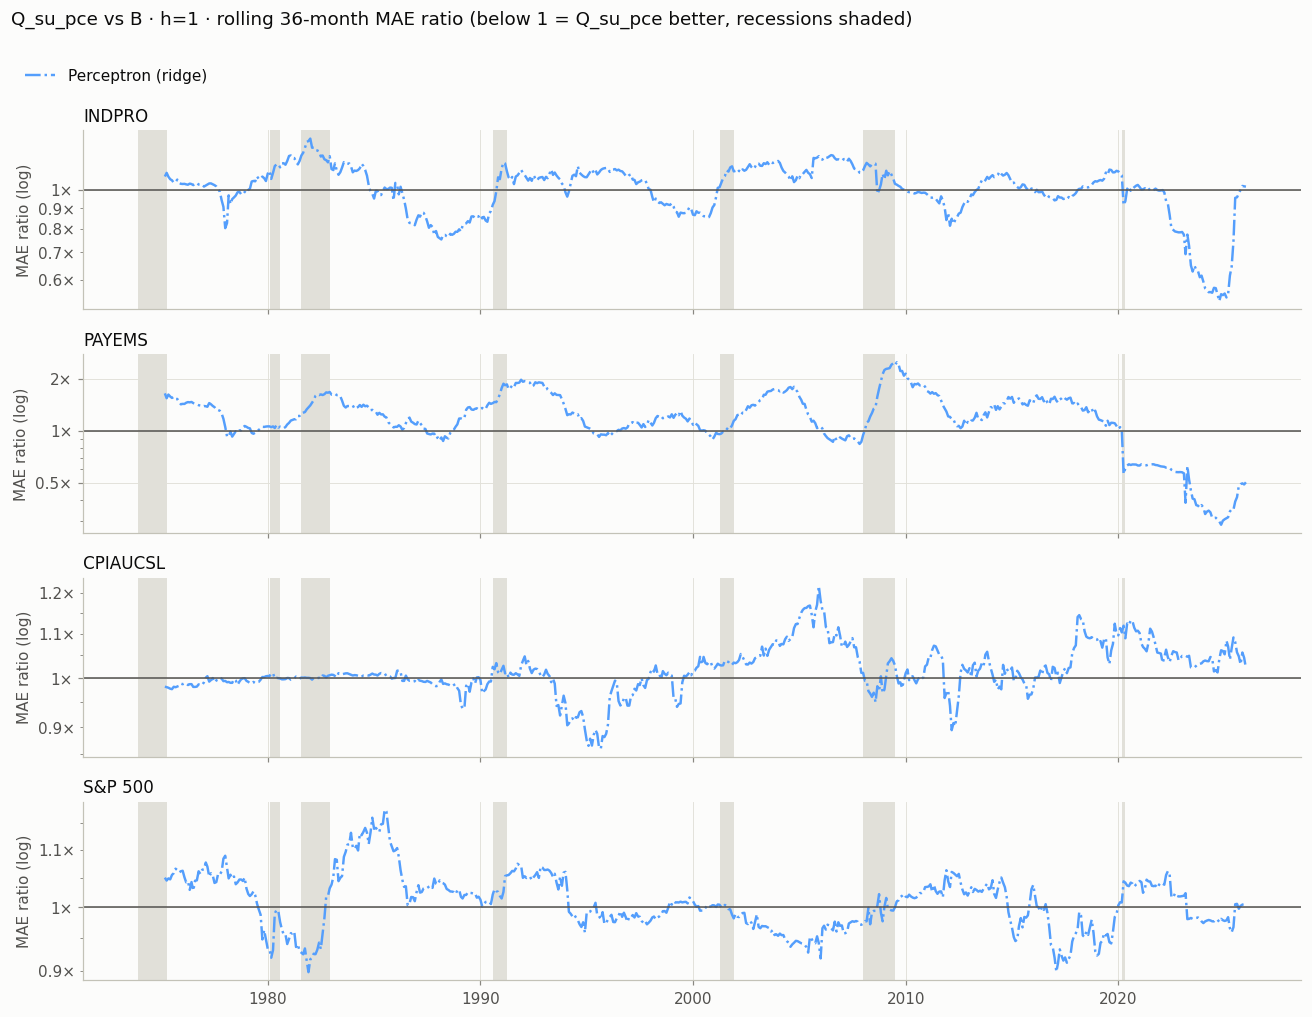

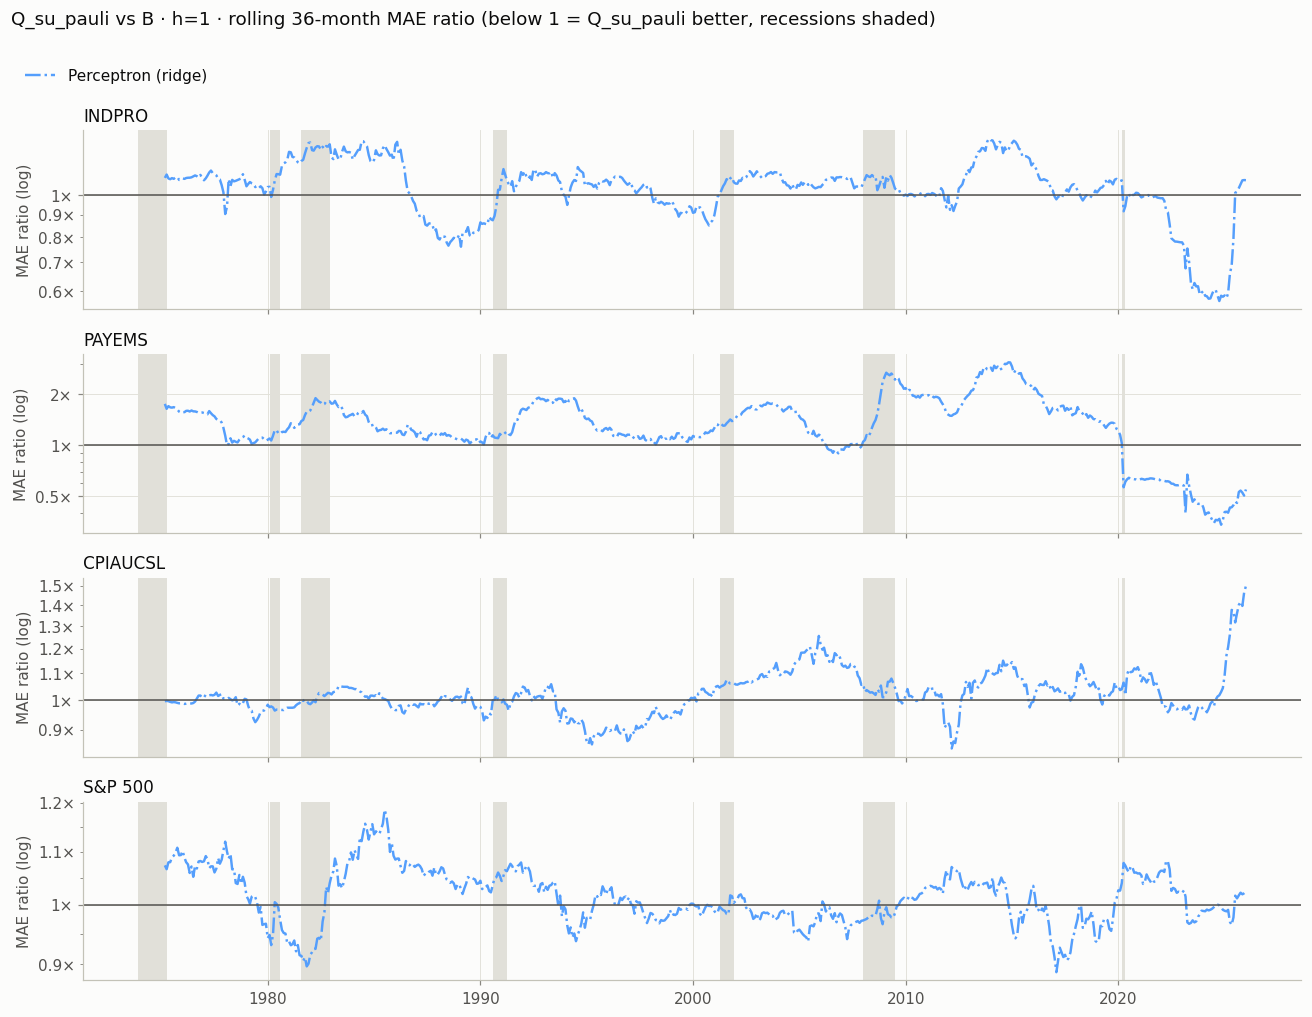

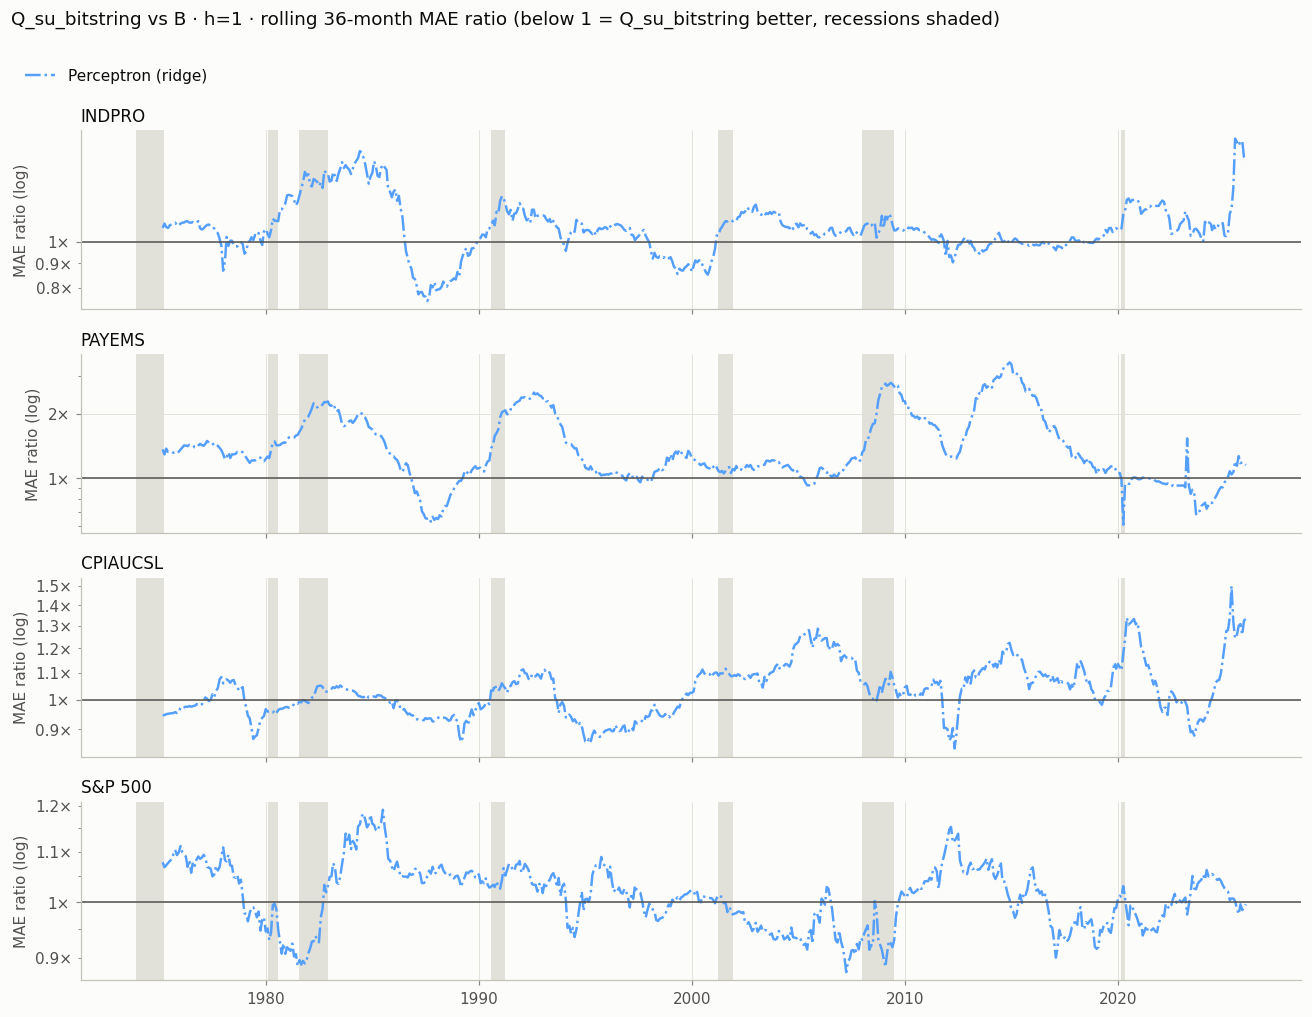

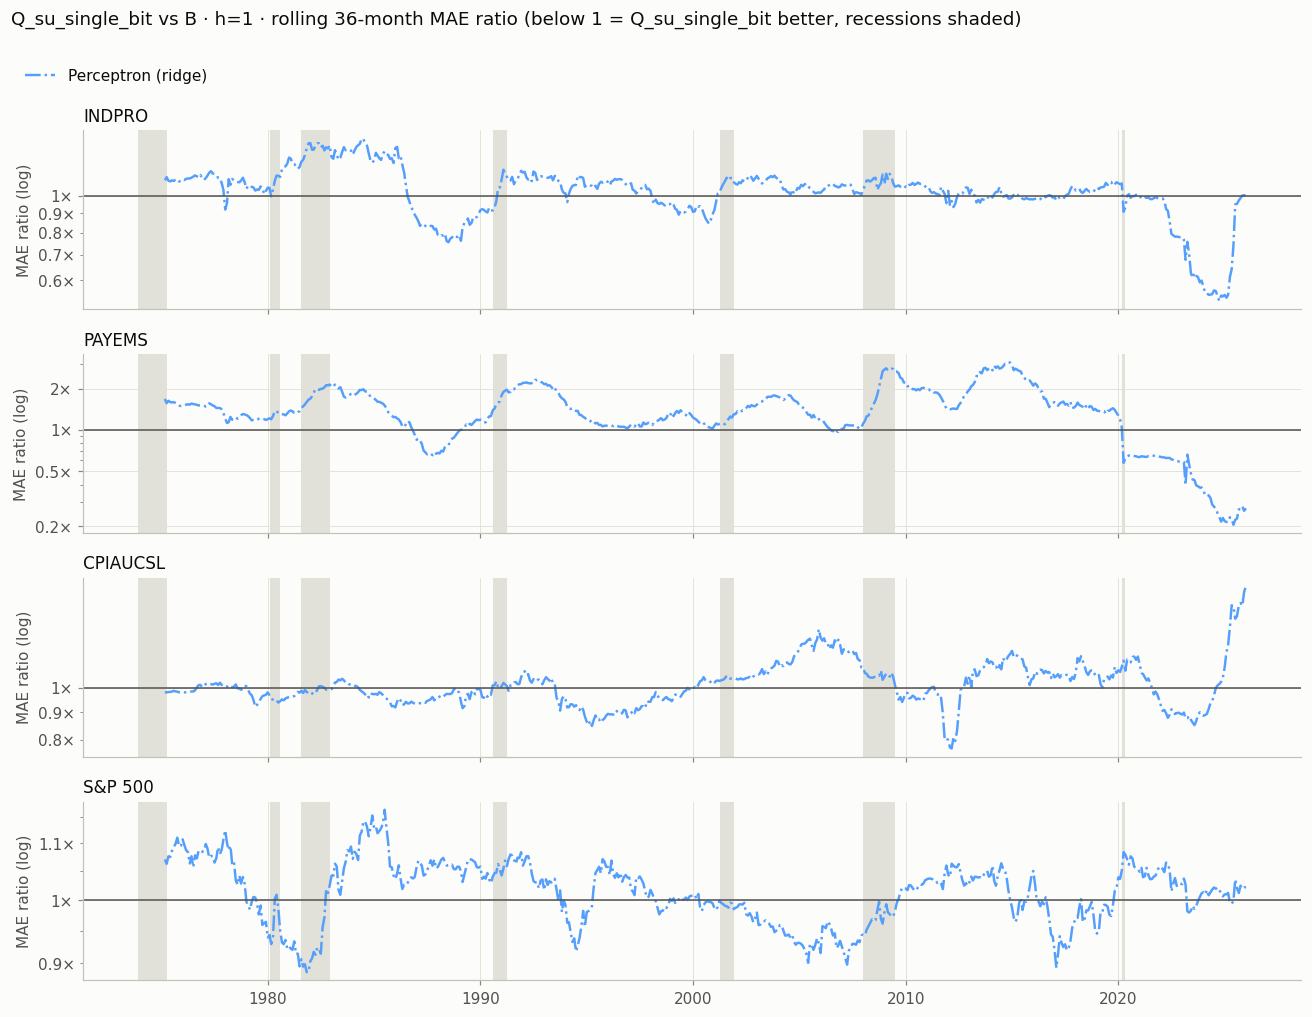

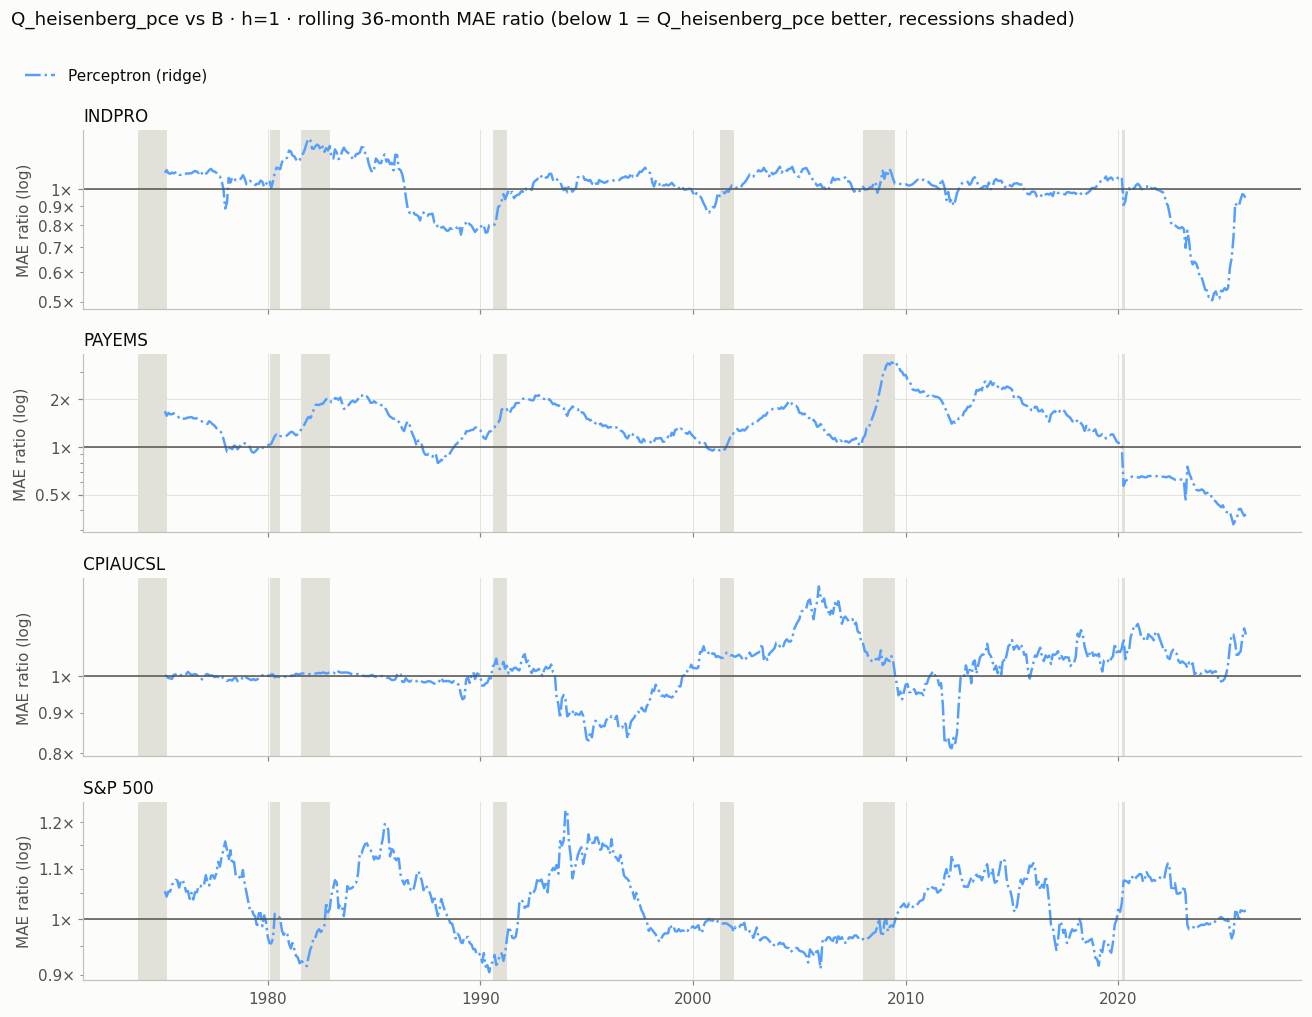

In [9]:
for q, c in pair_results:
    num = ok[(ok["track"] == q) & (ok["horizon"] == TIME_HORIZON)]
    den = ok[(ok["track"] == c) & (ok["horizon"] == TIME_HORIZON)]
    merged = num.merge(den[["model", *FOLD_KEYS, "mse", "mae"]], on=["model", *FOLD_KEYS], suffixes=("_n", "_d"))
    merged = merged[merged["model"].isin(pair_results[(q, c)].index.get_level_values("model"))]
    fig = rolling_ratio_figure(merged, f"{q} vs {c} · h={TIME_HORIZON} · rolling {ROLLING_WINDOW}-month MAE ratio "
                                       f"(below 1 = {q} better, recessions shaded)")
    save(fig, f"rolling_{q}_vs_{c}_h{TIME_HORIZON}")
    plt.show()
if not pair_results:
    print("No track pairs with results.")

## 5. Error over time

Rolling MAE of each model divided by the baseline's rolling MAE on `TIME_TRACK` at `TIME_HORIZON`. Grey bands are NBER recessions.

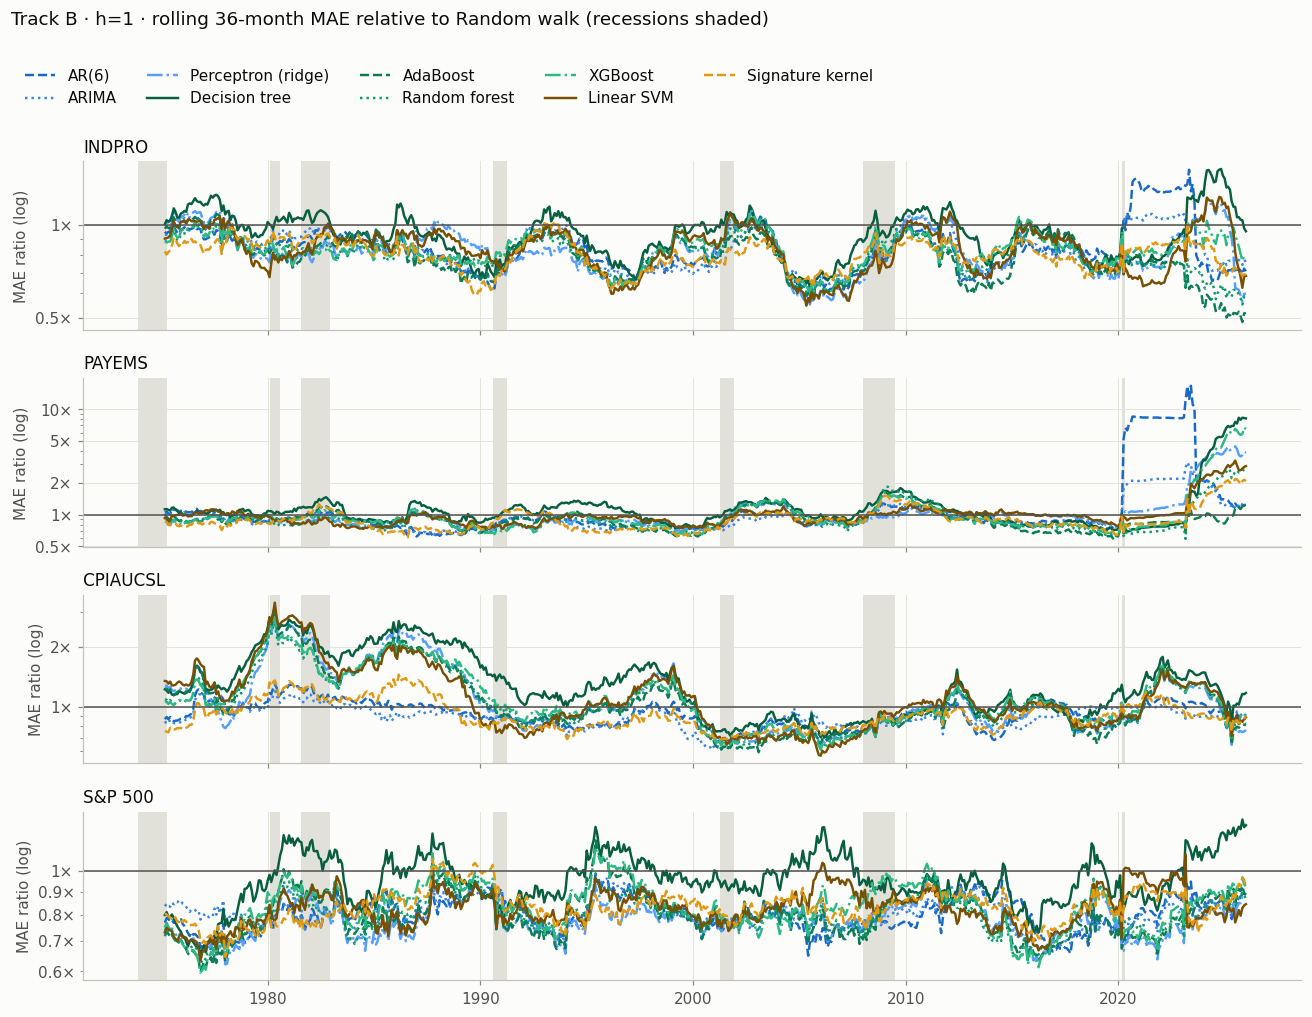

In [10]:
num = ok[(ok["track"] == TIME_TRACK) & (ok["horizon"] == TIME_HORIZON) & (ok["model"] != BASELINE_MODEL)]
den = base[(base["track"] == TIME_TRACK) & (base["horizon"] == TIME_HORIZON)]
merged = num.merge(den[["track", *FOLD_KEYS, "mse", "mae"]], on=["track", *FOLD_KEYS], suffixes=("_n", "_d"))
if merged.empty:
    print(f"No results for track {TIME_TRACK} at h={TIME_HORIZON} shared with the baseline.")
else:
    fig = rolling_ratio_figure(merged, f"Track {TIME_TRACK} · h={TIME_HORIZON} · rolling {ROLLING_WINDOW}-month MAE "
                                       f"relative to {mlabel(BASELINE_MODEL)} (recessions shaded)")
    save(fig, f"rolling_vs_baseline_{TIME_TRACK}_h{TIME_HORIZON}")
    plt.show()

## 6. Recessions vs expansions

RMSE relative to the baseline on `TIME_TRACK`, computed separately over test months in recessions (`USREC = 1`) and expansions (`USREC = 0`). Recession months are a small share of the sample, so those cells rest on far fewer folds.

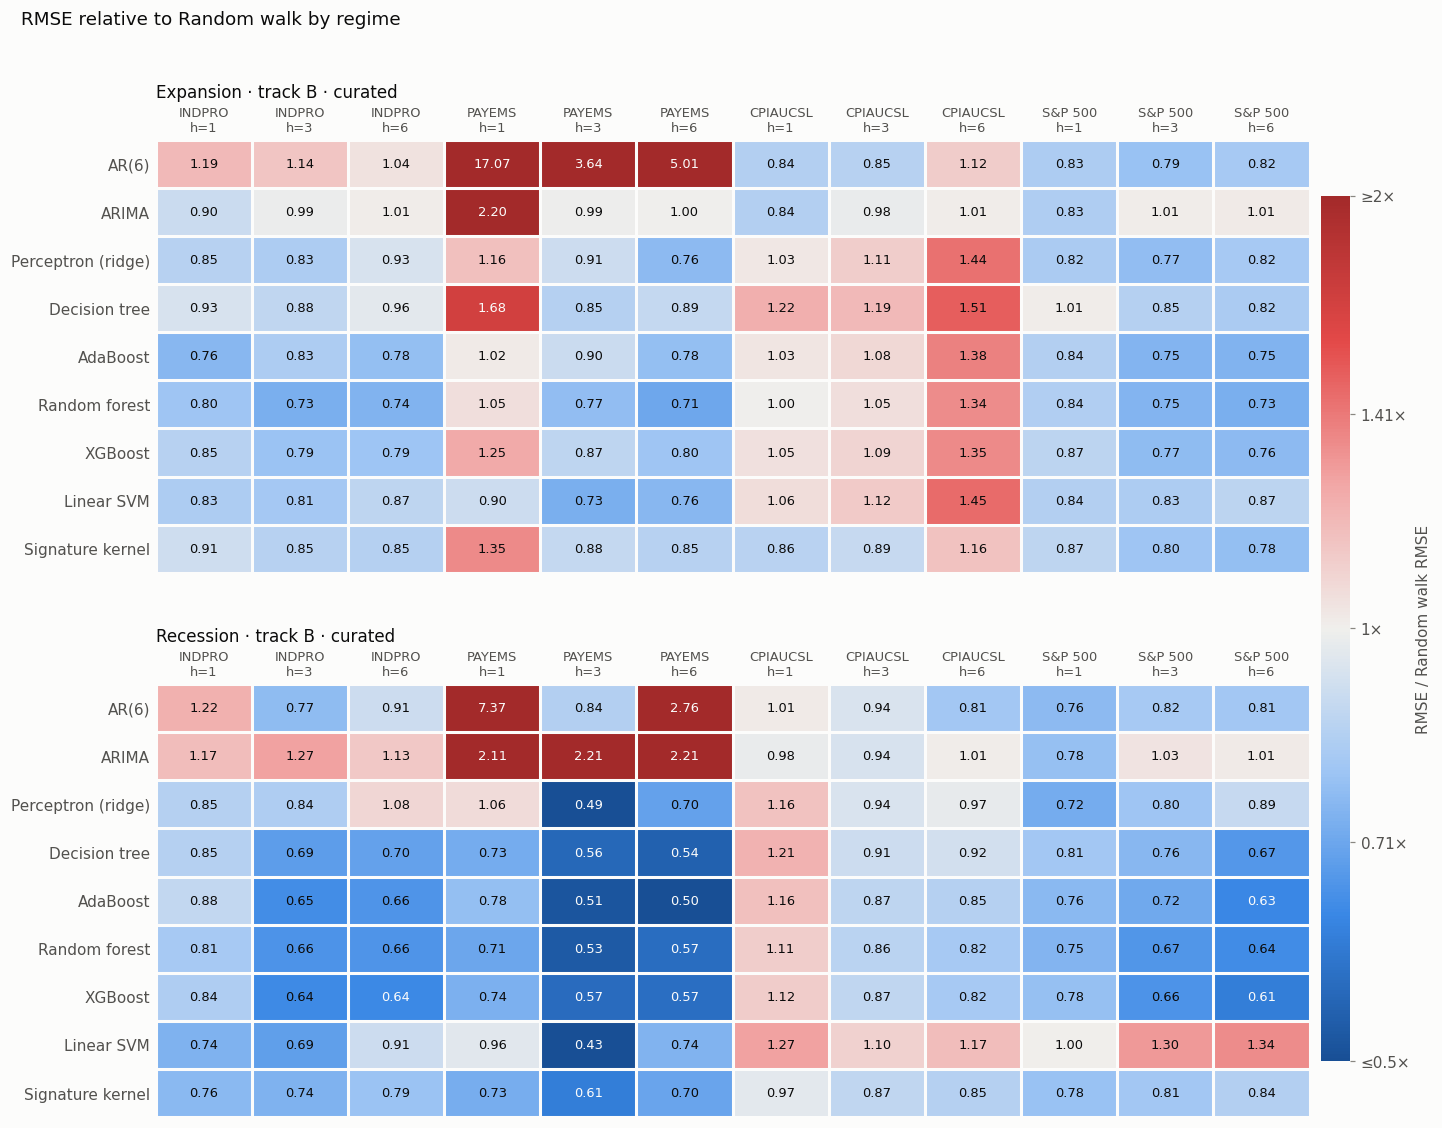

,test months
regime,
Expansion,572
Recession,74


In [11]:
tagged = ok[ok["track"] == TIME_TRACK].merge(usrec, left_on="test_start", right_index=True, how="left")
tagged["regime"] = tagged["usrec"].map({0: "Expansion", 1: "Recession"})
by_regime = matched_ratio(tagged[tagged["model"] != BASELINE_MODEL], tagged[tagged["model"] == BASELINE_MODEL],
                          on=["regime", *FOLD_KEYS], by=["regime", "model", "target", "horizon"])
if others and not by_regime.empty:
    panels = [(f"{regime} · track {tlabel(TIME_TRACK)}", wide(by_regime.loc[regime, "ratio"], others))
              for regime in ["Expansion", "Recession"] if regime in by_regime.index.get_level_values("regime")]
    fig = heatmap_figure(panels, f"RMSE relative to {mlabel(BASELINE_MODEL)} by regime", f"RMSE / {mlabel(BASELINE_MODEL)} RMSE")
    save(fig, f"relative_rmse_by_regime_{TIME_TRACK}")
    plt.show()
    display(tagged.groupby("regime")["test_start"].nunique().rename("test months").to_frame())
else:
    print(f"No results on track {TIME_TRACK} shared with the baseline.")

## 7. Example series: forecast vs actual

For each model in `MODEL_LIST`: its forecasts against the realised target over `EXAMPLE_PERIOD`, at `EXAMPLE_HORIZON`, one row per track in `EXAMPLE_TRACKS`. This needs stored predictions, which the current `02_evaluation_loop` saves; older result files only hold metrics, and models without predictions are listed at the end.

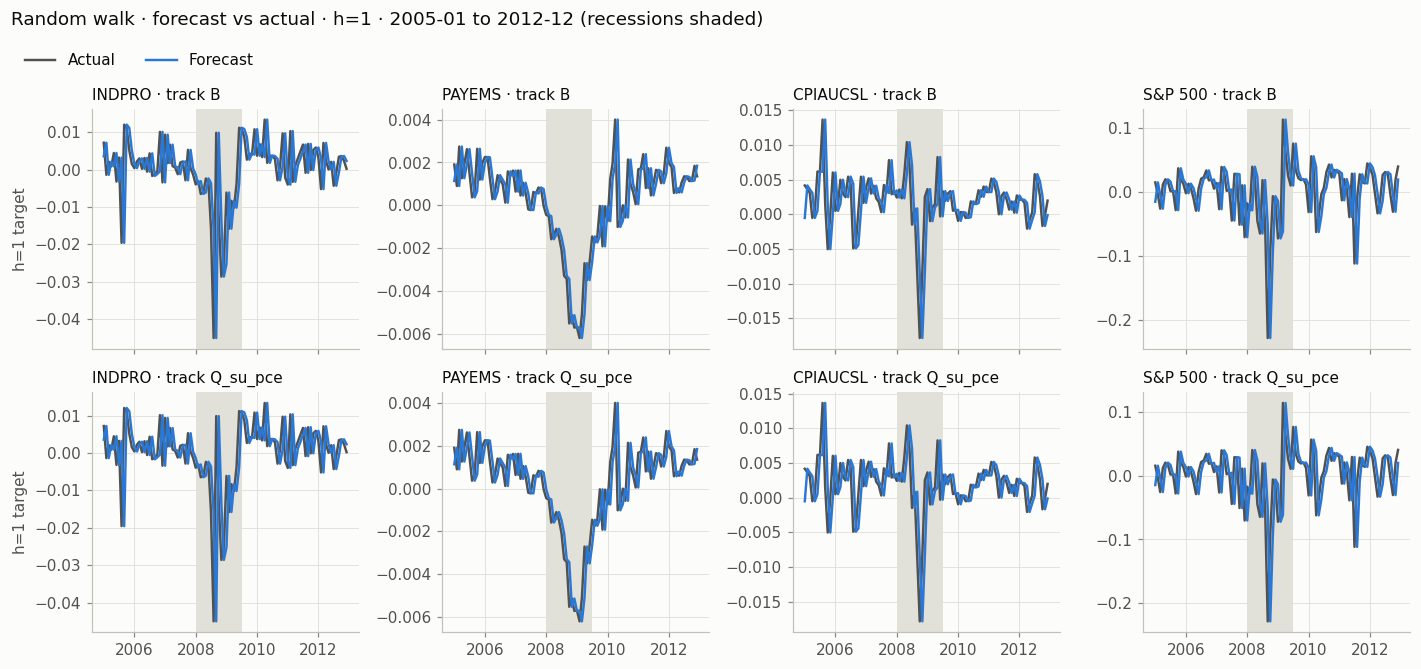

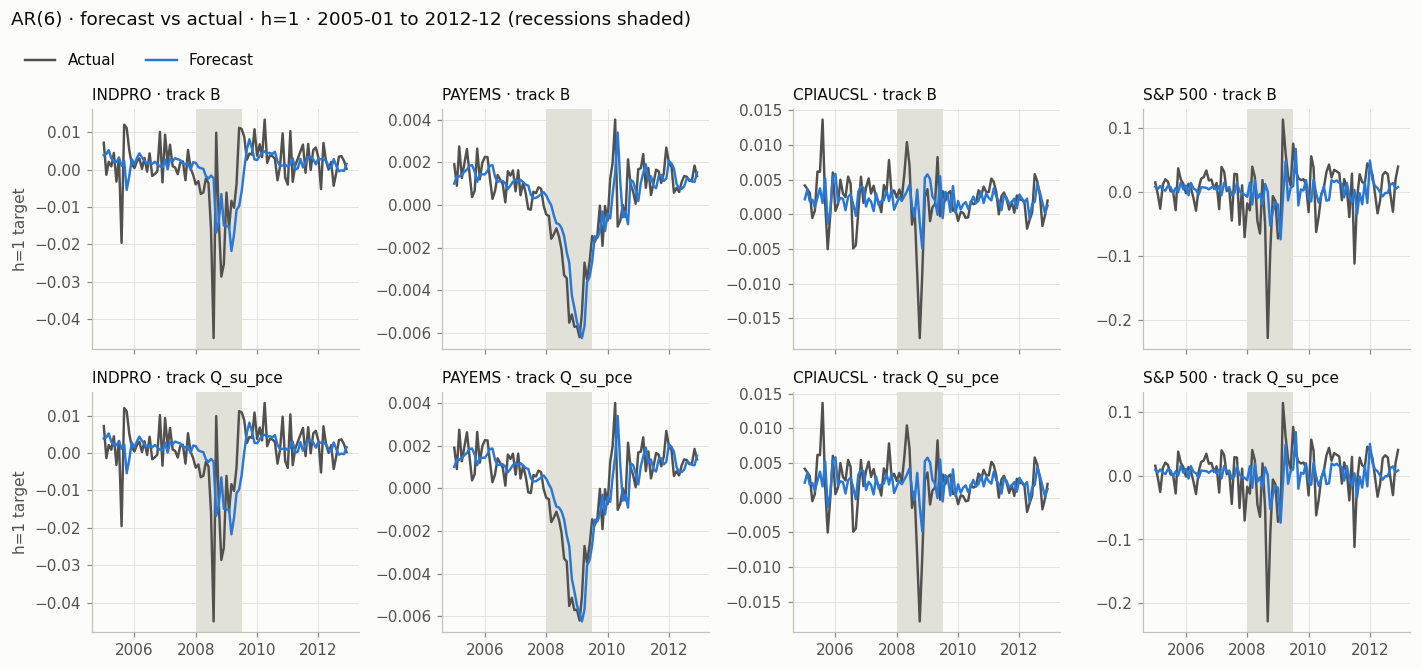

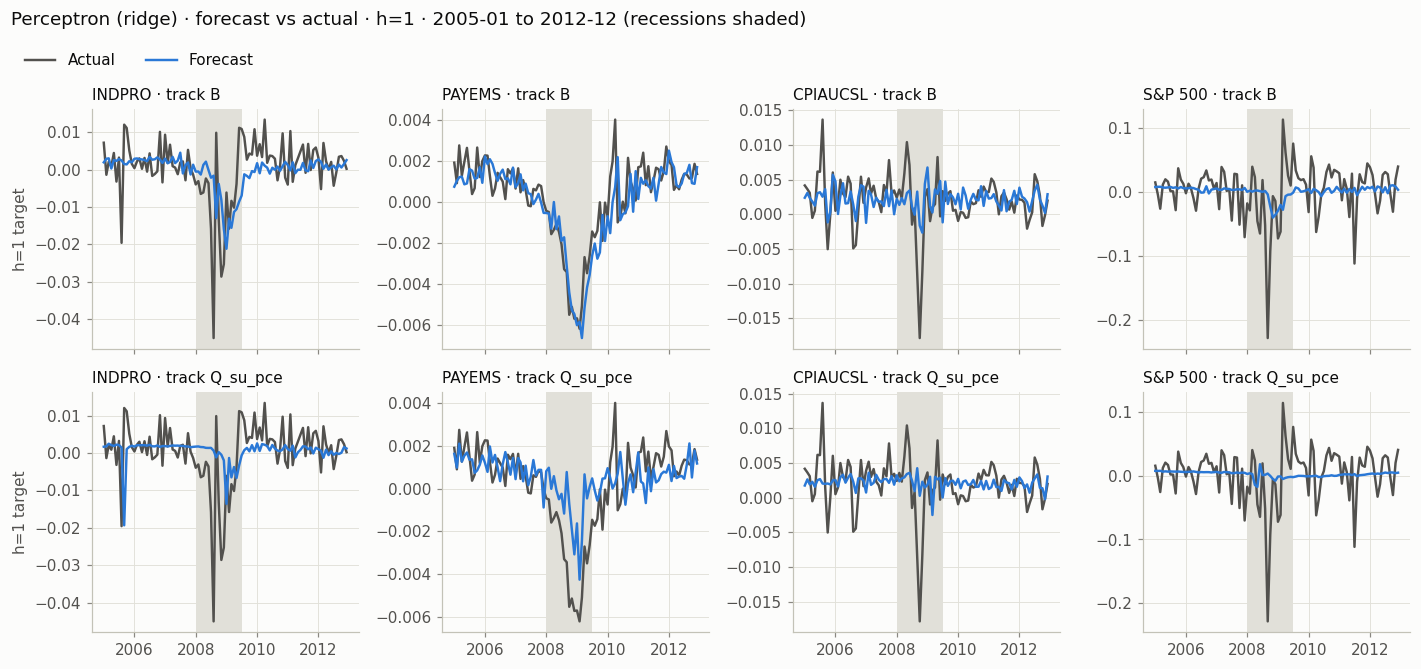

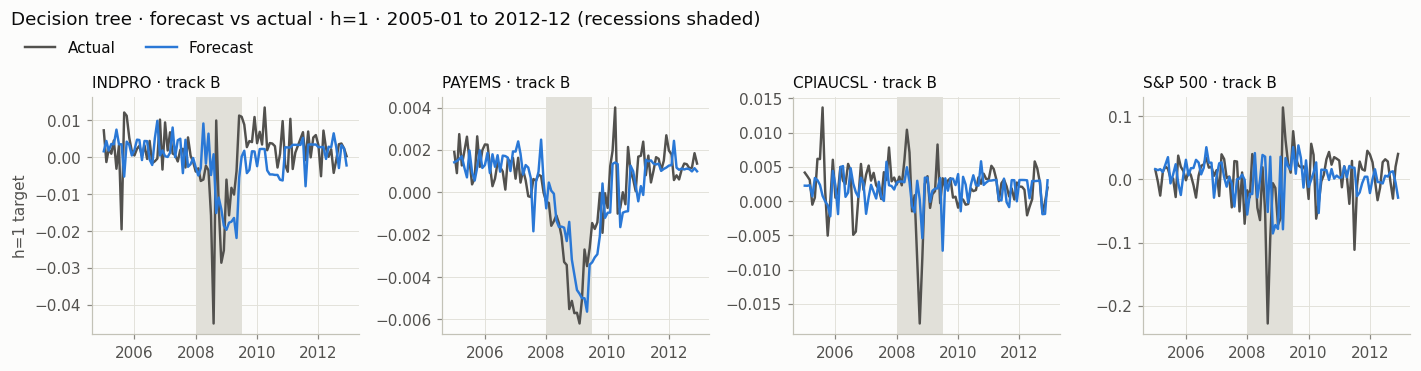

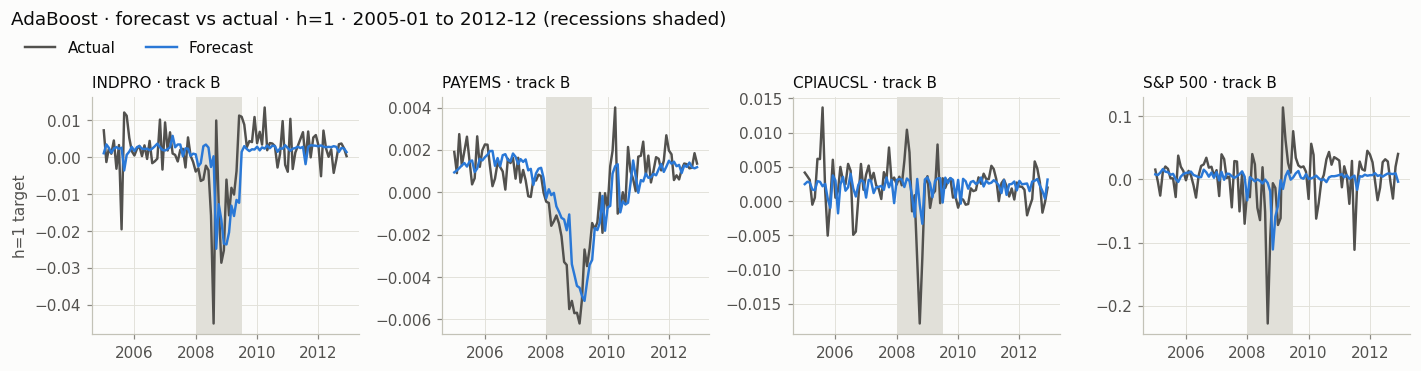

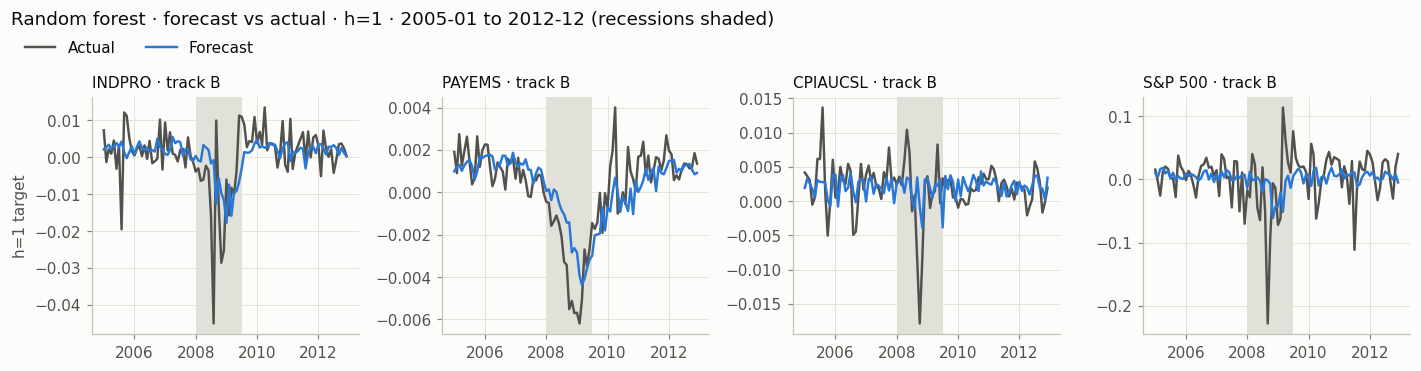

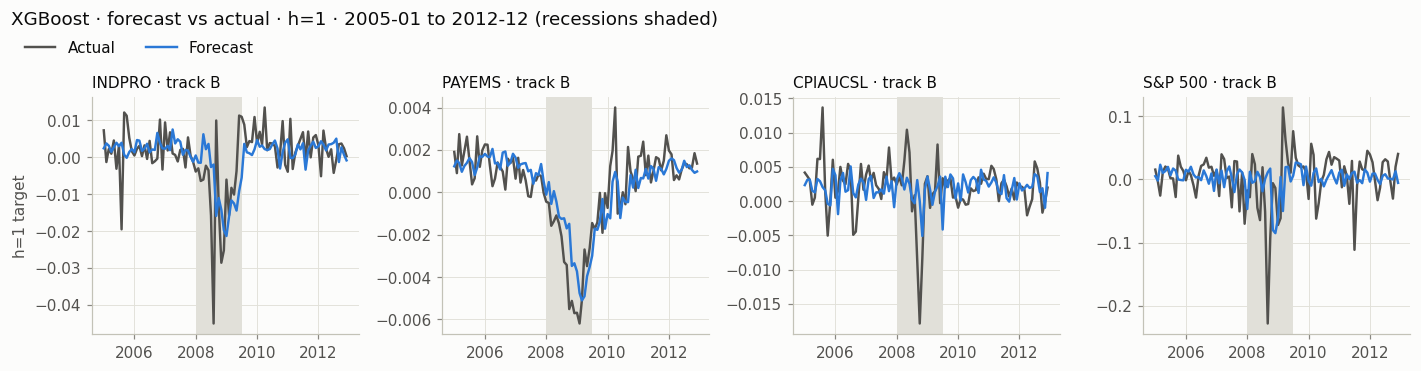

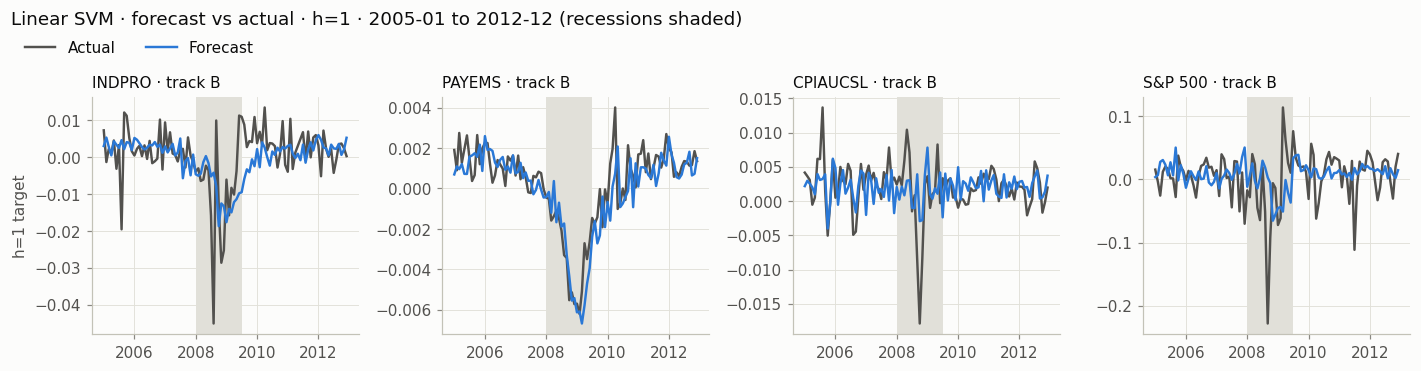

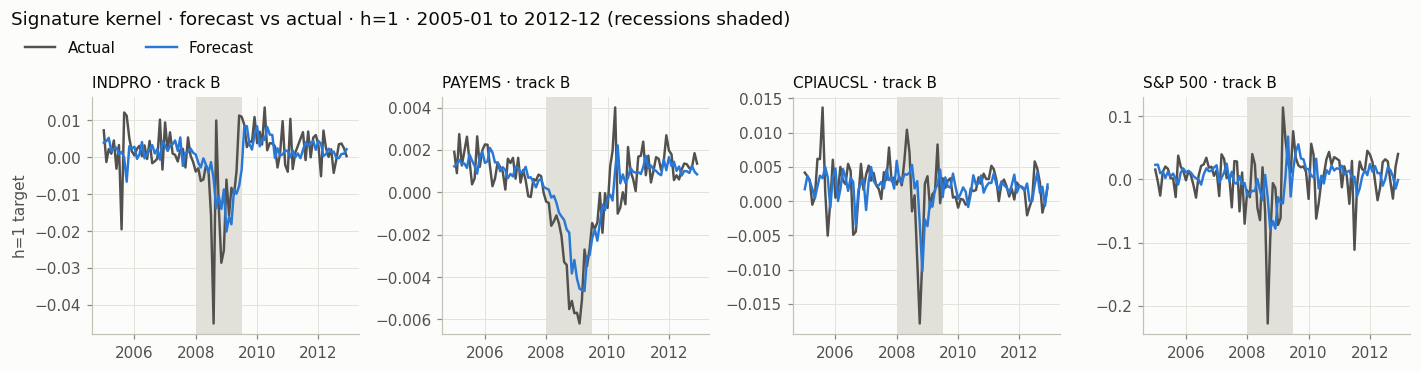

No stored predictions on tracks ['B', 'Q_su_pce'] between 2005-01 and 2012-12 for: ['arima'].
Re-run them with the current 02_evaluation_loop; RESUME=True redoes only runs that lack predictions.


In [12]:
start, end = map(pd.Timestamp, EXAMPLE_PERIOD)
tracks_ex = [t for t in EXAMPLE_TRACKS if t in TRACKS]
window = ok[(ok["horizon"] == EXAMPLE_HORIZON) & ok["track"].isin(tracks_ex)
            & (ok["test_end"] >= start) & (ok["test_start"] <= end)]
preds = explode_predictions(window)
preds = preds[(preds["date"] >= start) & (preds["date"] <= end)]

no_preds = []
for model in MODELS:
    mp = preds[preds["model"] == model]
    if mp.empty:
        no_preds.append(model)
        continue
    rows = [t for t in tracks_ex if t in set(mp["track"])]
    fig, axes = plt.subplots(len(rows), len(TARGETS), figsize=(13, 2.6 * len(rows) + 0.6), sharex=True, squeeze=False)
    for i, track in enumerate(rows):
        for j, target in enumerate(TARGETS):
            ax = axes[i, j]
            d = mp[(mp["track"] == track) & (mp["target"] == target)].sort_values("date")
            ax.set_title(f"{target} · track {track}" + ("" if len(d) else " · no data"), loc="left", fontsize=10)
            if d.empty:
                continue
            shade_recessions(ax, start, end)
            ax.plot(d["date"], d["y_true"], color=ACTUAL_COLOR, linewidth=1.6, label="Actual")
            ax.plot(d["date"], d["y_pred"], color=FORECAST_COLOR, linewidth=1.6, label="Forecast")
            ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=5))
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        axes[i, 0].set_ylabel(f"h={EXAMPLE_HORIZON} target")
    handles, labels = next((ax.get_legend_handles_labels() for ax in axes.flat if ax.lines), ([], []))
    fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.995), ncol=2)
    fig.suptitle(f"{mlabel(model)} · forecast vs actual · h={EXAMPLE_HORIZON} · "
                 f"{start:%Y-%m} to {end:%Y-%m} (recessions shaded)", x=0.01, y=1.04, ha="left", fontsize=12)
    fig.tight_layout()
    save(fig, f"forecast_vs_actual_{model}_h{EXAMPLE_HORIZON}")
    plt.show()

if no_preds:
    print(f"No stored predictions on tracks {tracks_ex} between {start:%Y-%m} and {end:%Y-%m} for: {no_preds}.\n"
          "Re-run them with the current 02_evaluation_loop; RESUME=True redoes only runs that lack predictions.")

## 8. Compute time

Total model fitting time recorded in `runtime_sec`, summed over every stored run. Useful for planning how long an evaluation run will take.

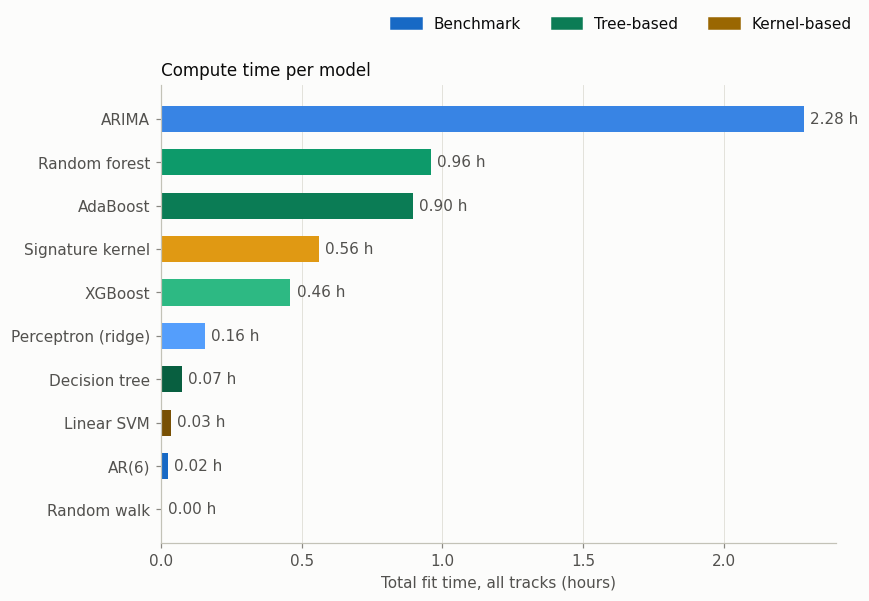

track,A,B,Q_heisenberg_pce,Q_su_bitstring,Q_su_pauli,Q_su_pce,Q_su_single_bit
model,,,,,,,
random_walk,NaN,0.000,0.000,0.000,0.000,0.000,0.000
AR6,NaN,0.004,0.004,0.004,0.004,0.004,0.004
arima,NaN,2.285,NaN,NaN,NaN,NaN,NaN
linear_readout,NaN,0.027,0.025,0.029,0.026,0.026,0.025
decision_tree,0.049,0.025,NaN,NaN,NaN,NaN,NaN
adaboost,0.613,0.283,NaN,NaN,NaN,NaN,NaN
random_forest,0.487,0.474,NaN,NaN,NaN,NaN,NaN
xgboost,0.366,0.094,NaN,NaN,NaN,NaN,NaN
linear_svm,NaN,0.035,NaN,NaN,NaN,NaN,NaN


In [13]:
runtime = ok.groupby(["model", "track"])["runtime_sec"].sum().div(3600).unstack("track").reindex(index=MODELS, columns=TRACKS)
total = runtime.sum(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.6 + 0.45 * len(total)))
ax.barh(range(len(total)), total.values, height=0.6, color=[MODEL_COLOR[m] for m in total.index])
ax.set_yticks(range(len(total)), [mlabel(m) for m in total.index])
for y, hours in enumerate(total.values):
    ax.annotate(f"{hours:.2f} h", (hours, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Total fit time, all tracks (hours)")
ax.set_title("Compute time per model", loc="left")
fig.tight_layout()
family_legend(fig, total.index, loc="lower right", bbox_to_anchor=(0.99, 1.0))
save(fig, "runtime")
plt.show()

runtime.round(3)

## 9. Metric by model

`metric_bar_chart(metric, track)` draws one panel per target with a bar per model, for any metric in the results (`mse`, `mae`, `median_ae`, `rmse`, `mase`, `rmspe`) at one horizon. Each panel has its own x-axis because the targets' scales differ. RMSE is pooled over folds as the square root of mean MSE; the other metrics are means over folds.

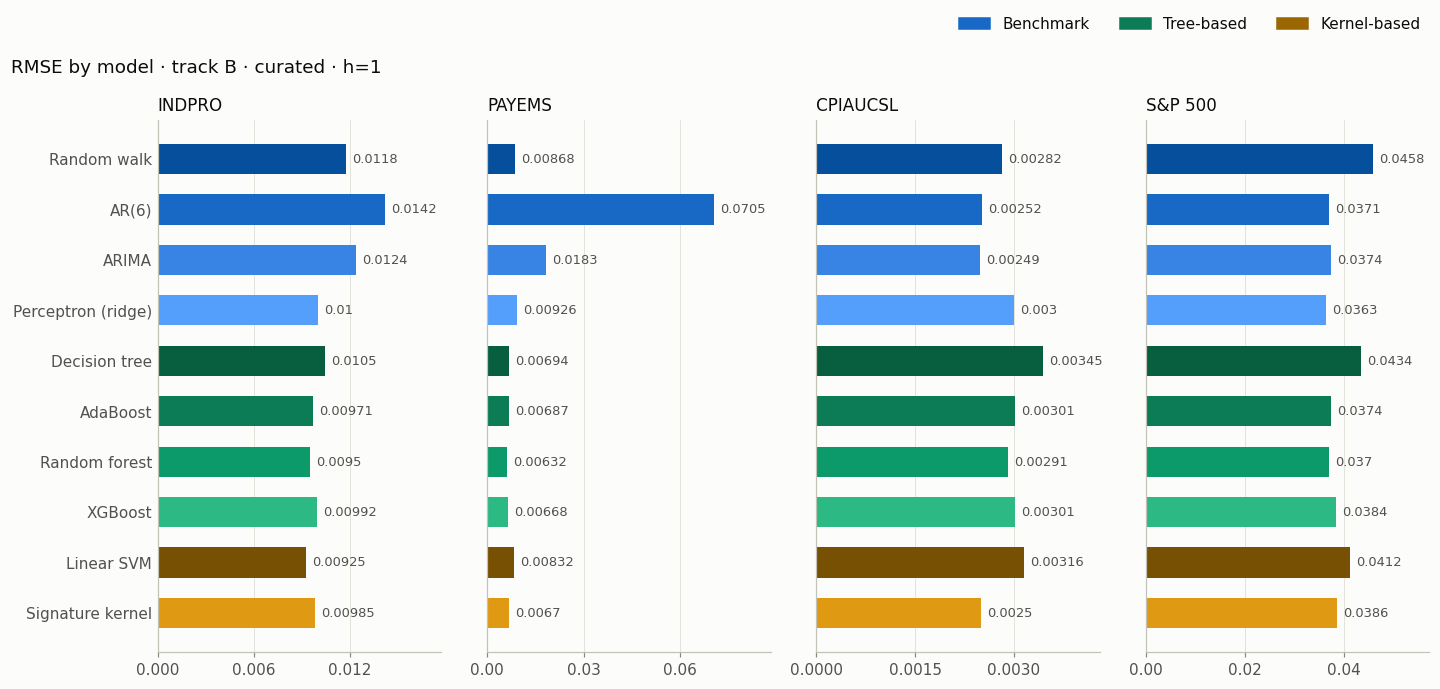

target,INDPRO,PAYEMS,CPIAUCSL,S&P 500
model,,,,
random_walk,0.011778,0.008678,0.002824,0.045811
AR6,0.014163,0.070491,0.002516,0.037076
arima,0.012390,0.018313,0.002490,0.037418
linear_readout,0.010012,0.009255,0.002997,0.036305
decision_tree,0.010469,0.006937,0.003446,0.043419
adaboost,0.009711,0.006875,0.003011,0.037387
random_forest,0.009498,0.006323,0.002908,0.037016
xgboost,0.009923,0.006684,0.003013,0.038418
linear_svm,0.009245,0.008317,0.003157,0.041237


In [14]:
METRIC_LABELS = {"mse": "MSE", "mae": "MAE", "median_ae": "Median AE", "rmse": "RMSE", "mase": "MASE", "rmspe": "RMSPE"}


def metric_bar_chart(metric, track, horizon=1, models=None):
    """
    Horizontal bar chart of one metric on one track: a panel per target, a bar per model.

    metric  : one of METRIC_LABELS (rmse is pooled as sqrt(mean mse); the rest are fold means)
    track   : a track with results, e.g. "B" or "Q_su_pce"
    horizon : forecast horizon to show
    models  : models to include (default: MODELS, in MODEL_LIST order)
    """
    if metric not in METRIC_LABELS:
        raise ValueError(f"Unknown metric {metric!r}; choose from {list(METRIC_LABELS)}")
    if track not in TRACKS:
        raise ValueError(f"No results for track {track!r}; have {TRACKS}")
    sub = ok[(ok["track"] == track) & (ok["horizon"] == horizon)]
    if sub.empty:
        raise ValueError(f"No results for track {track!r} at h={horizon}")
    g = sub.groupby(["target", "model"])
    values = g["mse"].mean() ** 0.5 if metric == "rmse" else g[metric].mean()
    rows = [m for m in (models or MODELS) if m in set(sub["model"])]

    fig, axes = plt.subplots(1, len(TARGETS), figsize=(3.3 * len(TARGETS), 0.45 * len(rows) + 1.4),
                             sharey=True, squeeze=False)
    y = np.arange(len(rows))
    for ax, target in zip(axes[0], TARGETS):
        v = values.get(target, pd.Series(dtype=float)).reindex(rows)
        ax.barh(y, v.fillna(0).values, height=0.6, color=[MODEL_COLOR[m] for m in rows])
        for yi, val in zip(y, v.values):
            label = "–" if np.isnan(val) else f"{val:.3g}"
            ax.annotate(label, (0 if np.isnan(val) else val, yi), xytext=(4, 0), textcoords="offset points",
                        va="center", fontsize=8.5, color=INK_2)
        ax.set_xlim(0, np.nanmax(v.values) * 1.25 if v.notna().any() else 1)
        ax.set_title(target, loc="left")
        ax.grid(axis="y", visible=False)
        ax.tick_params(axis="y", length=0)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(3))
    axes[0, 0].set_yticks(y, [mlabel(m) for m in rows])
    axes[0, 0].invert_yaxis()
    fig.suptitle(f"{METRIC_LABELS[metric]} by model · track {tlabel(track)} · h={horizon}", x=0.01, ha="left", fontsize=12)
    fig.tight_layout()
    family_legend(fig, rows, loc="lower right", bbox_to_anchor=(0.99, 1.0))
    save(fig, f"{metric}_by_model_{track}_h{horizon}")
    plt.show()
    return values.unstack("target").reindex(index=rows, columns=TARGETS)


metric_bar_chart("rmse", "B")